In [64]:
# imports
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
import warnings
warnings.filterwarnings('ignore')

# Set style for better plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")


In [65]:
# LOAD DATA

df1 = pd.read_excel("../../Enrol_model.xlsx")
df = df1.copy()
print(f"Dataset shape: {df.shape}")

Dataset shape: (725, 40)


In [66]:
# Handle Funded column
if 'Funded' not in df.columns:
    # Handle Funded column
    if 'Funded' not in df.columns:
        if 'Bursary Type' in df.columns:
            df['Funded'] = df['Bursary Type'].fillna('Self-Funded').apply(
                lambda x: 'No' if x == 'Self-Funded' else 'Yes'
            )
        else:
            df['Funded'] = 'No'

#Fill FUNDNAME with Self-Funded for missing
if 'FUNDNAME' in df.columns:
    df["FUNDNAME"] = df["FUNDNAME"].fillna("Self-Funded")

In [67]:

#DATA INSPECTION

print("DATA INSPECTION")
#Data types
print("\nData Types:")
print(df.dtypes.value_counts())

print("\nFirst 5 rows:")
display(df.head())

# 2.3 Column names
print(f"\nTotal columns: {len(df.columns)}")
print(df.columns.tolist())


DATA INSPECTION

Data Types:
object            26
float64           10
int64              4
datetime64[ns]     1
Name: count, dtype: int64

First 5 rows:


,Unnamed: 0,Academic Year,Faculty,Department Name,Identifier,Gender,Language Name,Ethnic Group Name,Country Name,Birthdate,...,MECHANICAL ENGINEERING MANUFACTURING,PHYSICAL SCIENCE,PROFESSIONAL COMMUNICATION,Average Marks,Res_status,RESIDENCE_NAME,Age_at_Registration,Downstream_Outcome,At_Risk,Funded
0,0,2022,ENGINEERING & BUILT ENVIRON.,MECHANICAL AND MECHATRONIC ENG,031cabecd64ce5caa03d22a2a271eadbbe2acc021a033f...,M,ENGLISH,COLOURED,R.S.A.,2001-07-04,...,75.0,71.0,65.0,76.142857,No,NaN,20,Graduated late,No,Yes
1,1,2022,ENGINEERING & BUILT ENVIRON.,MECHANICAL AND MECHATRONIC ENG,9adc4cfa1887f6ca47439a0dca8d068a5fed947a0e2820...,F,ENGLISH,COLOURED,R.S.A.,2000-07-12,...,59.0,50.0,68.0,55.857143,No,NaN,21,Graduated late,No,Yes
2,2,2025,ENGINEERING & BUILT ENVIRON.,MECHANICAL AND MECHATRONIC ENG,0c7a868d312a485253d66403713c6a55fbf68700d12930...,M,ENGLISH,INDIAN,R.S.A.,2006-09-12,...,80.0,59.0,68.0,66.857143,No,NaN,18,"Still enrolled (YOS 2, last 2026)",Yes,No
3,3,2022,ENGINEERING & BUILT ENVIRON.,MECHANICAL AND MECHATRONIC ENG,108b55b334d0e60ab104427cb03534360a20c200b18a9d...,M,XHOSA,AFRICAN,R.S.A.,2003-08-24,...,50.0,31.0,33.0,41.142857,No,NaN,18,Dropped out / transferred,Yes,Yes
4,4,2024,ENGINEERING & BUILT ENVIRON.,MECHANICAL AND MECHATRONIC ENG,195ef62dd8161b41d9eddce1c990ec12d9186ce286552e...,M,ENGLISH,COLOURED,R.S.A.,2005-11-18,...,61.0,69.0,64.0,67.714286,No,NaN,18,"Still enrolled (YOS 3, last 2026)",No,Yes



Total columns: 41
['Unnamed: 0', 'Academic Year', 'Faculty', 'Department Name', 'Identifier', 'Gender', 'Language Name', 'Ethnic Group Name', 'Country Name', 'Birthdate', 'Qualification Code', 'Qualification Name', 'Offering Type', 'Campus Name', 'Period Of Study', 'Ften Status This Year', 'Previous Activity Desc', 'Marital Status', 'Matric Type', 'Secondary School Name', 'Qualification Type', 'Post Graduate', 'Student Type Description', 'School Quintile', 'Formal Time', 'Bursary Type', 'FUNDNAME', 'COMPUTER SKILLS AND APPLICATIONS', 'ENGINEERING DRAWING 1', 'ENGINEERING MATHEMATICS', 'ENGINEERING MECHANICS', 'MECHANICAL ENGINEERING MANUFACTURING', 'PHYSICAL SCIENCE', 'PROFESSIONAL COMMUNICATION', 'Average Marks', 'Res_status', 'RESIDENCE_NAME', 'Age_at_Registration', 'Downstream_Outcome', 'At_Risk', 'Funded']


In [68]:

# DROP UNNECESSARY COLUMNS
drop_cols = [
    'Birthdate','Unnamed: 0', 'Formal Time', 'Average Marks',
    'Faculty', 'Department Name', 'Qualification Code', 'Qualification Name', 
    'Offering Type', 'Campus Name', 'Period Of Study', 'Qualification Type',
    'Post Graduate', 'RESIDENCE_NAME','Matric Type',
 'Secondary School Name','Marital Status',
]

# Only drop columns that exist in the dataframe
existing_drop_cols = [col for col in drop_cols if col in df.columns]
df = df.drop(columns=existing_drop_cols, errors='ignore')

print(f"Dropped columns: {existing_drop_cols}")
print(f"Dataset after dropping columns: {df.shape}")


Dropped columns: ['Birthdate', 'Unnamed: 0', 'Formal Time', 'Average Marks', 'Faculty', 'Department Name', 'Qualification Code', 'Qualification Name', 'Offering Type', 'Campus Name', 'Period Of Study', 'Qualification Type', 'Post Graduate', 'RESIDENCE_NAME', 'Matric Type', 'Secondary School Name', 'Marital Status']
Dataset after dropping columns: (725, 24)


In [69]:
df.columns.tolist()

['Academic Year',
 'Identifier',
 'Gender',
 'Language Name',
 'Ethnic Group Name',
 'Country Name',
 'Ften Status This Year',
 'Previous Activity Desc',
 'Student Type Description',
 'School Quintile',
 'Bursary Type',
 'FUNDNAME',
 'COMPUTER SKILLS AND APPLICATIONS',
 'ENGINEERING DRAWING 1',
 'ENGINEERING MATHEMATICS',
 'ENGINEERING MECHANICS',
 'MECHANICAL ENGINEERING MANUFACTURING',
 'PHYSICAL SCIENCE',
 'PROFESSIONAL COMMUNICATION',
 'Res_status',
 'Age_at_Registration',
 'Downstream_Outcome',
 'At_Risk',
 'Funded']

In [70]:
MODULES = [
    'COMPUTER SKILLS AND APPLICATIONS',
    'ENGINEERING DRAWING 1',
    'ENGINEERING MATHEMATICS',
    'ENGINEERING MECHANICS',
    'MECHANICAL ENGINEERING MANUFACTURING',
    'PHYSICAL SCIENCE',
    'PROFESSIONAL COMMUNICATION',
]
# Count how many modules each student is registered for
# (assuming non-null values mean registered)
student_module_counts = df[MODULES].notna().sum(axis=1)

# Create frequency table of how many students have each number of registrations
reg_distribution = student_module_counts.value_counts().sort_index().reset_index()
reg_distribution.columns = ['Number of Modules', 'Number of Students']

# Add percentage column
reg_distribution['Percentage (%)'] = round(
    (reg_distribution['Number of Students'] / len(df)) * 100, 2
)

print(f"Total students in dataset: {len(df)}")
print()
print(reg_distribution.to_string(index=False))

# Optional: Add cumulative statistics
print()
print("Summary Statistics:")
print(f"Mean modules per student: {student_module_counts.mean():.2f}")
print(f"Median modules per student: {student_module_counts.median():.0f}")
print(f"Min modules registered: {student_module_counts.min()}")
print(f"Max modules registered: {student_module_counts.max()}")

Total students in dataset: 725

 Number of Modules  Number of Students  Percentage (%)
                 1                   1            0.14
                 2                   1            0.14
                 3                   2            0.28
                 4                  11            1.52
                 5                   6            0.83
                 6                  24            3.31
                 7                 680           93.79

Summary Statistics:
Mean modules per student: 6.88
Median modules per student: 7
Min modules registered: 1
Max modules registered: 7


# Exploratory Data Analysis

MISSING VALUES ANALYSIS
                                      Missing   Percent
ENGINEERING DRAWING 1                      40  5.517241
MECHANICAL ENGINEERING MANUFACTURING       13  1.793103
ENGINEERING MATHEMATICS                    10  1.379310
PHYSICAL SCIENCE                            8  1.103448
ENGINEERING MECHANICS                       7  0.965517
School Quintile                             6  0.827586
COMPUTER SKILLS AND APPLICATIONS            5  0.689655
PROFESSIONAL COMMUNICATION                  5  0.689655


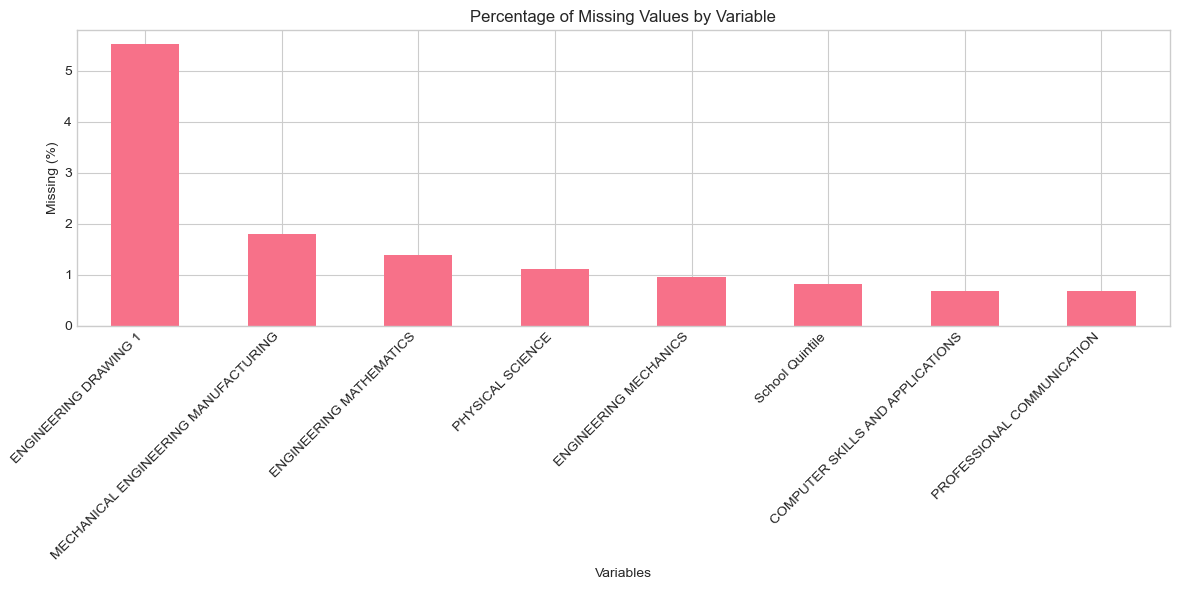

In [71]:
#MISSING VALUES ANALYSIS

print("MISSING VALUES ANALYSIS")

missing_df = pd.DataFrame({
    'Missing': df.isnull().sum(),
    'Percent': (df.isnull().sum() / len(df)) * 100
})
missing_df = missing_df[missing_df['Missing'] > 0].sort_values('Percent', ascending=False)
print(missing_df)

# Visualize missing values
if len(missing_df) > 0:
    plt.figure(figsize=(12, 6))
    missing_df['Percent'].plot(kind='bar')
    plt.title('Percentage of Missing Values by Variable')
    plt.xlabel('Variables')
    plt.ylabel('Missing (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


In [72]:
# Fill no in Funded Column for NaN values
#f['Funded'] = df['Funded'].fillna('No')

In [73]:

df = df[student_module_counts == 7].reset_index(drop=True)
print(f"\nDropped {reg_distribution[reg_distribution['Number of Modules'] < 7]['Number of Students'].sum()} students")
print(f"Remaining students: {len(df)}")



Dropped 45 students
Remaining students: 680


**Interpretation**

Most variables contain little or no missing data. only the marks column show high missing values. the low propotion of missing data suggests that the dataset is of good quality, appropiate imputations techniques can be applied without substantially affecting the integrity of the analysis. 

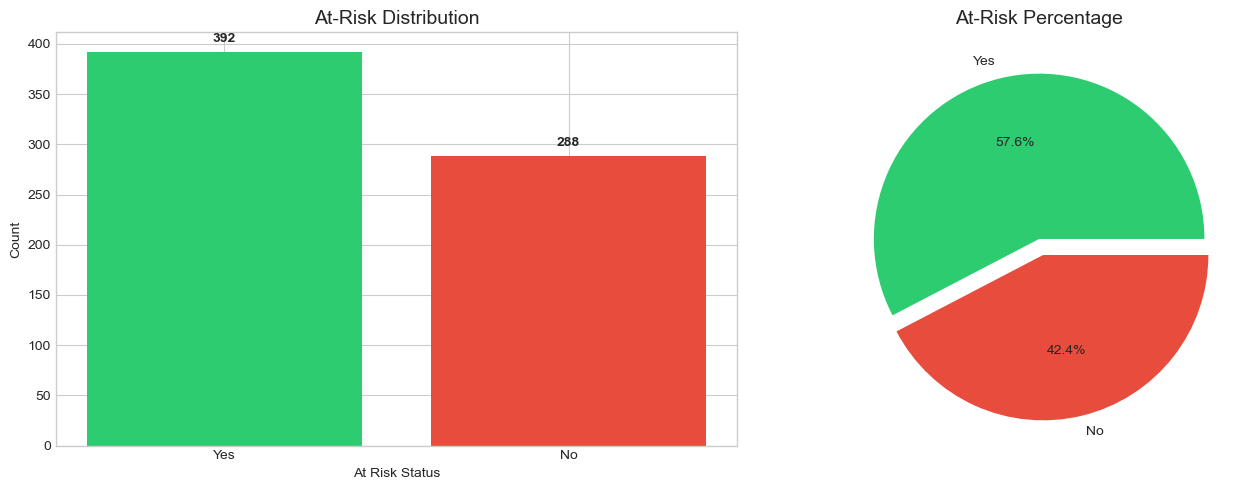


Target variable distribution:
Not At-Risk: 288 (42.4%)
At-Risk: 392 (57.6%)


In [74]:
# 5.1 Target Variable Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
risk_counts = df['At_Risk'].value_counts()
axes[0].bar(risk_counts.index, risk_counts.values, color=['#2ecc71', '#e74c3c'])
axes[0].set_title('At-Risk Distribution', fontsize=14)
axes[0].set_xlabel('At Risk Status')
axes[0].set_ylabel('Count')
for i, v in enumerate(risk_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(risk_counts.values, labels=risk_counts.index, autopct='%1.1f%%',
            colors=['#2ecc71', '#e74c3c'], explode=(0, 0.1))
axes[1].set_title('At-Risk Percentage', fontsize=14)
plt.tight_layout()
plt.show()

print(f"\nTarget variable distribution:")
print(f"Not At-Risk: {risk_counts.get('No', 0)} ({risk_counts.get('No', 0)/len(df)*100:.1f}%)")
print(f"At-Risk: {risk_counts.get('Yes', 0)} ({risk_counts.get('Yes', 0)/len(df)*100:.1f}%)")



Numerical Variables Summary:


,Academic Year,School Quintile,COMPUTER SKILLS AND APPLICATIONS,ENGINEERING DRAWING 1,ENGINEERING MATHEMATICS,ENGINEERING MECHANICS,MECHANICAL ENGINEERING MANUFACTURING,PHYSICAL SCIENCE,PROFESSIONAL COMMUNICATION,Age_at_Registration
count,680.000000,674.000000,680.000000,680.000000,680.000000,680.000000,680.000000,680.000000,680.000000,680.000000
mean,2023.841176,3.259644,60.555882,49.479412,48.088235,53.291176,55.854412,54.816176,58.289706,18.991176
std,1.124665,1.376713,14.598902,20.780489,19.319144,15.921399,14.478392,13.563793,12.609107,1.773619
min,2022.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000
25%,2023.000000,2.000000,56.000000,36.000000,35.000000,44.000000,50.000000,50.000000,53.000000,18.000000
50%,2024.000000,3.000000,63.000000,53.000000,51.000000,55.000000,57.000000,57.000000,60.000000,19.000000
75%,2025.000000,5.000000,69.000000,64.000000,61.000000,64.000000,65.000000,63.000000,66.250000,20.000000
max,2025.000000,5.000000,89.000000,92.000000,91.000000,87.000000,84.000000,81.000000,83.000000,33.000000


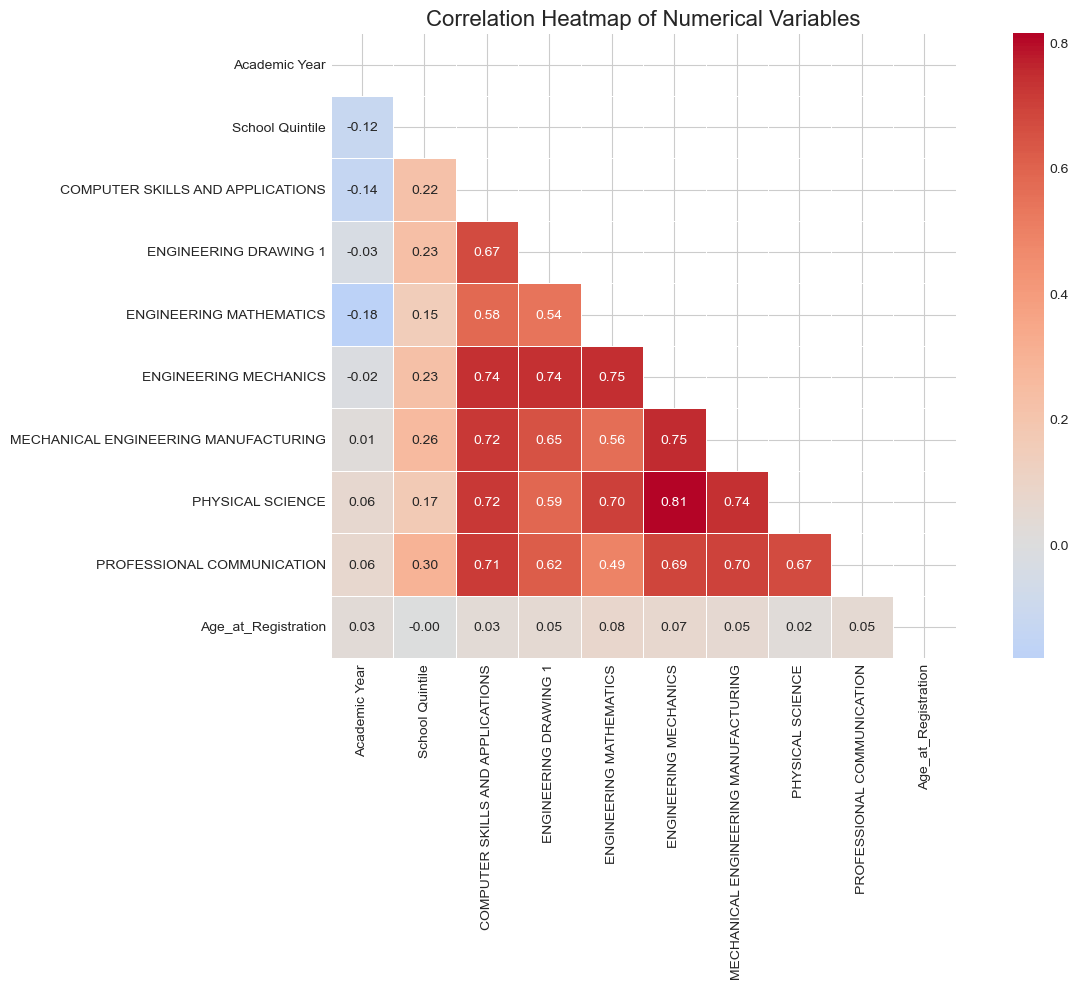

In [75]:

# 5.2 Numerical Summary Statistics
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
# Remove target from numeric columns
if 'At_Risk' in numeric_cols:
    numeric_cols.remove('At_Risk')

print("\nNumerical Variables Summary:")
display(df[numeric_cols].describe())

# Correlation Heatmap
if len(numeric_cols) > 1:
    plt.figure(figsize=(14, 10))
    corr_matrix = df[numeric_cols].corr()
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', center=0, 
                annot=True, fmt='.2f', square=True, linewidths=0.5)
    plt.title('Correlation Heatmap of Numerical Variables', fontsize=16)
    plt.tight_layout()
    plt.show()


**Correlation HeatMap**

the correlation matrix illustrates the strength and direction of linear relationship among numerical variables. subjects echibit moderate positive correlations with one another. positive correlations indicate that the students who perform well in one subject often perfom well in related subjects. however, no correlation appears high to indicate sever multicollinearity which means the subjects capyure different aspects of student success.

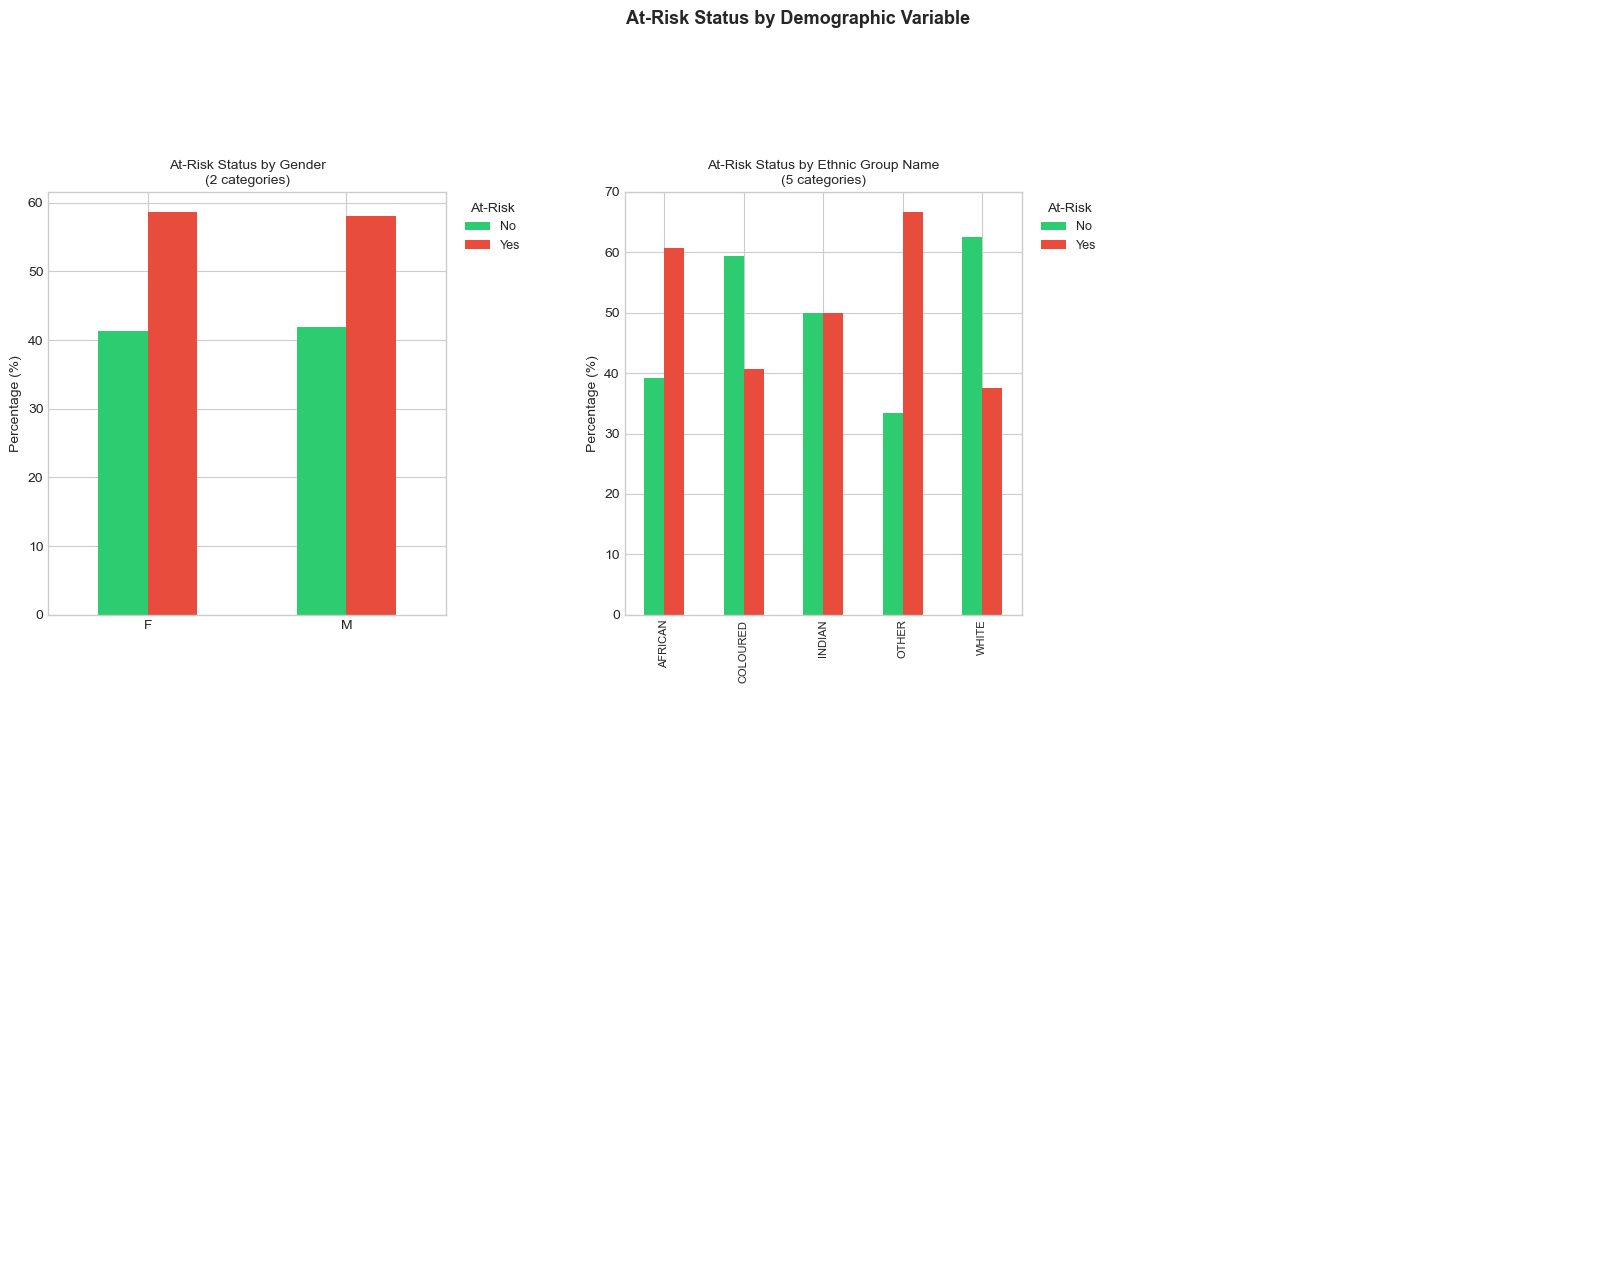

In [116]:
# Demographic Summaries
demographic_cols = ['Gender', 'Language Name', 'Ethnic Group Name', 'Country Name',
                    'Marital Status', 'School Quintile', 'Matric Type']

existing_demo = [col for col in demographic_cols if col in df.columns]

# Columns with many categories need extra space
HIGH_CARDINALITY = {'Language Name', 'Ethnic Group Name', 'Country Name',
                    'Previous Activity Desc'}

if existing_demo:
    fig, axes = plt.subplots(2, 3, figsize=(20, 14))
    axes = axes.flatten()

    for i, col in enumerate(existing_demo[:6]):
        ax = axes[i]
        risk_by_demo = pd.crosstab(df[col], df['At_Risk'], normalize='index') * 100

        risk_by_demo.plot(kind='bar', ax=ax, stacked=False,
                          color=['#2ecc71', '#e74c3c'])

        ax.set_title(f'At-Risk Status by {col}', fontsize=11, pad=8)
        ax.set_xlabel('')          # remove redundant x-axis label
        ax.set_ylabel('Percentage (%)', fontsize=10)
        ax.legend(title='At-Risk', bbox_to_anchor=(1.02, 1),
                  loc='upper left', fontsize=9)

        # Choose label style based on number of categories
        n_cats = len(risk_by_demo)
        if col in HIGH_CARDINALITY or n_cats > 6:
            # Many categories: rotate fully horizontal and shrink font
            ax.set_xticklabels(
                ax.get_xticklabels(),
                rotation=90,
                ha='center',
                fontsize=8
            )
        elif n_cats > 4:
            # Medium: 45 degrees
            ax.set_xticklabels(
                ax.get_xticklabels(),
                rotation=45,
                ha='right',
                fontsize=9
            )
        else:
            # Few categories: flat labels are fine
            ax.set_xticklabels(
                ax.get_xticklabels(),
                rotation=0,
                ha='center',
                fontsize=10
            )

        # Add category count to subtitle so reader knows how many groups
        ax.set_title(f'At-Risk Status by {col}\n({n_cats} categories)',
                     fontsize=10, pad=6)

    # Hide unused subplots
    for j in range(len(existing_demo[:6]), len(axes)):
        axes[j].axis('off')

    # Extra bottom margin for rotated labels
    plt.subplots_adjust(hspace=0.55, wspace=0.45)
    plt.suptitle('At-Risk Status by Demographic Variable', 
                 fontsize=13, fontweight='bold', y=1.01)
    plt.show()

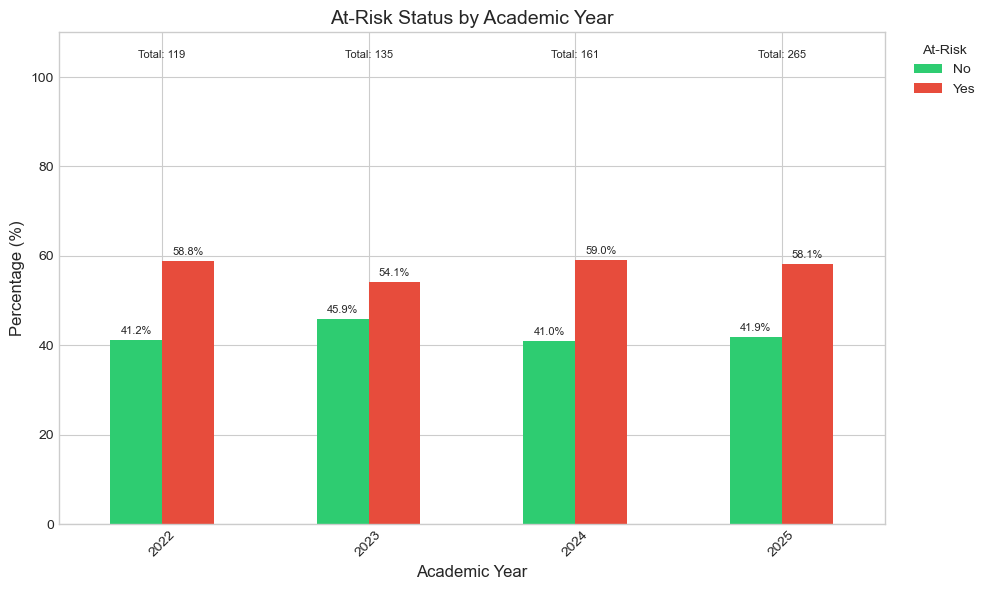

In [77]:
# Distribution of At-Risk by Academic Year
academic_year = df['Academic Year'].astype(str)
risk_by_year = pd.crosstab(academic_year, df['At_Risk'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(10, 6))
risk_by_year.plot(
    kind='bar',
    stacked=False,
    ax=ax,
    color=['#2ecc71', '#e74c3c']
)

ax.set_title('At-Risk Status by Academic Year', fontsize=14)
ax.set_xlabel('Academic Year', fontsize=12)
ax.set_ylabel('Percentage (%)', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.set_ylim(0, 110)

# Label each grouped bar at its actual position.
for container, status in zip(ax.containers, risk_by_year.columns):
    for bar, percentage in zip(container, risk_by_year[status]):
        if percentage > 0:
            ax.annotate(
                f'{percentage:.1f}%',
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center',
                va='bottom',
                fontsize=8,
                xytext=(0, 3),
                textcoords='offset points'
            )

# Show the cohort size above each academic year.
for index, year in enumerate(risk_by_year.index):
    total_students = (academic_year == year).sum()
    ax.text(index, 106, f'Total: {total_students}', ha='center', va='top', fontsize=8)

ax.legend(title='At-Risk', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
plt.show()

# Feature Engineering

# Handle Funded column
if 'Funded' not in df.columns:
    # Handle Funded column
    if 'Funded' not in df.columns:
        if 'Bursary Type' in df.columns:
            df['Funded'] = df['Bursary Type'].fillna('Self-Funded').apply(
                lambda x: 'No' if x == 'Self-Funded' else 'Yes'
            )
        else:
            df['Funded'] = 'No'

#Fill FUNDNAME with Self-Funded for missing
if 'FUNDNAME' in df.columns:
    df["FUNDNAME"] = df["FUNDNAME"].fillna("Self-Funded")

# Handle Residence Status
if 'Res_status' in df.columns:
    df['Res_status'] = df['Res_status'].fillna('No')

# Remove leakage column
leakage_cols = ['Subjects Failed', 'Subjects Passed', 'Other Subjects']
df = df.drop(columns=[col for col in leakage_cols if col in df.columns], errors='ignore')

print(f"Dataset after feature engineering: {df.shape}")


In [78]:
#  FEATURE ENCODING STRATEGY

# For ordinal encoding 
ordinal_cols = ['Gender', 'Res_status', 'Funded']

# For one-hot encoding (nominal variables)
nominal_cols = [
    'Language Name', 'Ethnic Group Name', 'Country Name',
    'Previous Activity Desc', 'Marital Status', 'Matric Type',
    'Student Type Description', 'FUNDNAME'
]

# Numeric columns (excluding target)
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'At_Risk' in numeric_cols:
    numeric_cols.remove('At_Risk')

# Check which columns actually exist in the dataset
ordinal_cols = [col for col in ordinal_cols if col in df.columns]
nominal_cols = [col for col in nominal_cols if col in df.columns]

print(f"Ordinal columns (binary/ordered): {len(ordinal_cols)}")
print(f"Nominal columns (one-hot): {len(nominal_cols)}")
print(f"Numeric columns: {len(numeric_cols)}")


Ordinal columns (binary/ordered): 3
Nominal columns (one-hot): 6
Numeric columns: 10


# Modelling

In [79]:
# TRAIN-TEST SPLIT

# Ensure target is binary
df['At_Risk'] = df['At_Risk'].map({'Yes': 1, 'No': 0})

X = df.drop(columns=['At_Risk'])
y = df['At_Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"Training target distribution:")
print(y_train.value_counts(normalize=True))
print(f"\nTest target distribution:")
print(y_test.value_counts(normalize=True))


Training set: 544 samples
Test set: 136 samples
Training target distribution:
At_Risk
1    0.577206
0    0.422794
Name: proportion, dtype: float64

Test target distribution:
At_Risk
1    0.573529
0    0.426471
Name: proportion, dtype: float64


The distribution of the target variable indicates the proportion of students classified as At Risk and Not At Risk. Although the classes are not perfectly balanced, both categories contain a sufficient number of observations for model development. 

# Shared Feature-Importance Utilities

In [80]:
# DATA PREPROCESSING PIPELINE
# For Random Forest (tree-based model, no feature scaling needed)
rf_preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numeric_cols),
        ('ordinal', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        ]), ordinal_cols),
        ('nominal', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), nominal_cols)
    ]
)

print(f"Random Forest preprocessor: numeric({len(numeric_cols)}) + ordinal({len(ordinal_cols)}) + nominal({len(nominal_cols)})")


Random Forest preprocessor: numeric(10) + ordinal(3) + nominal(6)


In [81]:
# SHARED UTILITIES
# aggregate_feature_importance() collapses one-hot encoded columns back to their
# original feature name (e.g. all "Language Name_XHOSA", "Language Name_ENGLISH", ...
# one-hot columns collapse back into a single "Language Name" row).
# Used by both the Random Forest and SVM importance sections below.

def aggregate_feature_importance(raw_importance):
    """
    Aggregate one-hot encoded features back to original column names
    """
    aggregated = {}

    for feature, importance in zip(raw_importance['Feature'], raw_importance['Importance']):
        if '__' in feature:
            parts = feature.split('__', 1)
            prefix = parts[0]
            col_name = parts[1]

            if prefix == 'nominal':
                if '_' in col_name:
                    original_col = col_name.split('_')[0]
                else:
                    original_col = col_name
            else:
                original_col = col_name
        else:
            original_col = feature

        if original_col in aggregated:
            aggregated[original_col] += importance
        else:
            aggregated[original_col] = importance

    agg_df = pd.DataFrame({
        'Feature': list(aggregated.keys()),
        'Importance': list(aggregated.values())
    }).sort_values('Importance', ascending=False)

    return agg_df

# The seven foundational first-year modules (used to isolate module-only importance)
module_cols = [
    'COMPUTER SKILLS AND APPLICATIONS',
    'ENGINEERING DRAWING 1',
    'ENGINEERING MATHEMATICS',
    'ENGINEERING MECHANICS',
    'MECHANICAL ENGINEERING MANUFACTURING',
    'PHYSICAL SCIENCE',
    'PROFESSIONAL COMMUNICATION'
]


# Feature Selection (Chi-Square)

Shared chi-square feature-selection step, reused by the SVM-with-FS model below.

In [82]:
# PREPROCESS DATA FOR FEATURE SELECTION
# We need to transform the data first to apply Chi-square

# Create a preprocessor that outputs numpy array
preprocessor_for_fs = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())  # Scale for SVM, but Chi-square needs non-negative
        ]), numeric_cols),
        ('ordinal', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        ]), ordinal_cols),
        ('nominal', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), nominal_cols)
    ]
)

# Fit and transform training data
X_train_preprocessed = preprocessor_for_fs.fit_transform(X_train, y_train)
X_test_preprocessed = preprocessor_for_fs.transform(X_test)

print(f"Preprocessed training data shape: {X_train_preprocessed.shape}")
print(f"Preprocessed test data shape: {X_test_preprocessed.shape}")

Preprocessed training data shape: (544, 66)
Preprocessed test data shape: (136, 66)


In [83]:
# Chi-square feature selection
from sklearn.feature_selection import SelectKBest, chi2, f_classif
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression

# Chi-square requires non-negative features
# Scale to [0,1] for chi2
scaler_minmax = MinMaxScaler()
X_train_scaled = scaler_minmax.fit_transform(X_train_preprocessed)
X_test_scaled = scaler_minmax.transform(X_test_preprocessed)

# Get feature names for reference
feature_names = preprocessor_for_fs.get_feature_names_out()

# Apply Chi-square feature selection
# Try different k values, scoring each with a fast probe classifier
# (Logistic Regression -- used only to pick k, not one of our final models)
k_values = [10, 15, 20, 25, 30]
best_k = None
best_cv_score = 0

for k in k_values:
    selector = SelectKBest(chi2, k=k)
    X_train_selected = selector.fit_transform(X_train_scaled, y_train)

    # Quick cross-validation to choose best k
    probe_clf = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    cv_scores = cross_val_score(probe_clf, X_train_selected, y_train, cv=5, scoring='recall')
    mean_score = cv_scores.mean()

    print(f"k={k}: CV Recall = {mean_score:.4f}")

    if mean_score > best_cv_score:
        best_cv_score = mean_score
        best_k = k

print(f"\nBest k value: {best_k} with CV Recall: {best_cv_score:.4f}")

# Get selected feature mask
selector_best = SelectKBest(chi2, k=best_k)
X_train_selected = selector_best.fit_transform(X_train_scaled, y_train)
X_test_selected = selector_best.transform(X_test_scaled)

# Get selected feature names
selected_mask = selector_best.get_support()
selected_features = feature_names[selected_mask]
print(f"\nSelected {len(selected_features)} features")
print("Top 10 selected features:")
print(selected_features[:10])


k=10: CV Recall = 0.8950
k=15: CV Recall = 0.9014
k=20: CV Recall = 0.9110
k=25: CV Recall = 0.8919
k=30: CV Recall = 0.8919

Best k value: 20 with CV Recall: 0.9110

Selected 20 features
Top 10 selected features:
['num__COMPUTER SKILLS AND APPLICATIONS' 'num__ENGINEERING DRAWING 1'
 'num__ENGINEERING MATHEMATICS' 'num__ENGINEERING MECHANICS'
 'num__MECHANICAL ENGINEERING MANUFACTURING' 'num__PHYSICAL SCIENCE'
 'num__PROFESSIONAL COMMUNICATION' 'nominal__Language Name_AFRIKAANS'
 'nominal__Language Name_ENGLISH' 'nominal__Language Name_PORTUGUESE']


# Support Vector Machine

In [84]:
#For SVM (with scaling)
svm_preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),
        ('ordinal', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        ]), ordinal_cols),
        ('nominal', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), nominal_cols)
    ]
)

print("Preprocessing pipelines created:")
print(f"SVM: numeric({len(numeric_cols)}) + ordinal({len(ordinal_cols)}) + nominal({len(nominal_cols)})")

Preprocessing pipelines created:
SVM: numeric(10) + ordinal(3) + nominal(6)


SVM PERFORMANCE:
Cross-validation Recall (mean): 0.9046 (+/- 0.0263)
Test Accuracy: 0.8971
Test Precision: 0.9706
Test Recall: 0.8462
Test F1-Score: 0.9041
Test ROC-AUC: 0.9768

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89        58
           1       0.97      0.85      0.90        78

    accuracy                           0.90       136
   macro avg       0.90      0.91      0.90       136
weighted avg       0.91      0.90      0.90       136



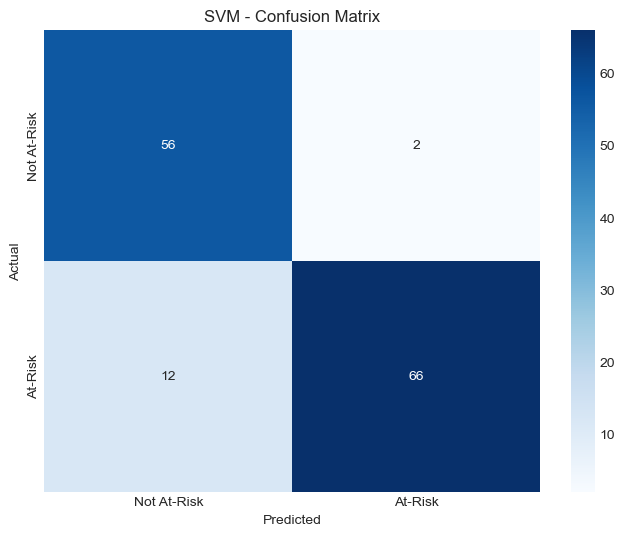

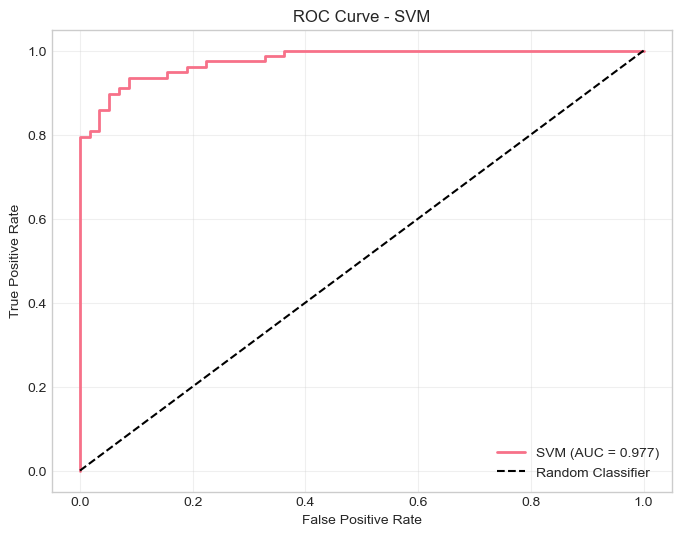

In [85]:
#SVM MODEL

svm_model = Pipeline([
    ('preprocess', svm_preprocessor),
    ('classifier', SVC(
        kernel='rbf',
        probability=True,
        class_weight='balanced',
        random_state=42,
        C=1.0,
        gamma='scale'
    ))
])

# Fit SVM
svm_model.fit(X_train, y_train)

# Predictions
y_pred_svm = svm_model.predict(X_test)
y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

# Cross-validation
cv_scores_svm = cross_val_score(svm_model, X_train, y_train, cv=5, scoring='recall')

print("SVM PERFORMANCE:")
print(f"Cross-validation Recall (mean): {cv_scores_svm.mean():.4f} (+/- {cv_scores_svm.std():.4f})")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"Test Precision: {precision_score(y_test, y_pred_svm):.4f}")
print(f"Test Recall: {recall_score(y_test, y_pred_svm):.4f}")
print(f"Test F1-Score: {f1_score(y_test, y_pred_svm):.4f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_prob_svm):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

# Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not At-Risk', 'At-Risk'],
            yticklabels=['Not At-Risk', 'At-Risk'])
plt.title('SVM - Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ROC Curve
fig, ax = plt.subplots(figsize=(8, 6))
fpr, tpr, _ = roc_curve(y_test, y_prob_svm)
plt.plot(fpr, tpr, label=f'SVM (AUC = {roc_auc_score(y_test, y_prob_svm):.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - SVM')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Training data shape: (544, 66)
Test data shape: (136, 66)
Number of features: 66
Computing SHAP values... (this may take a moment)


  0%|          | 0/30 [00:00<?, ?it/s]

SHAP values shape: 30
SHAP values shape: (30, 66, 2)
Test sample shape: (30, 66)


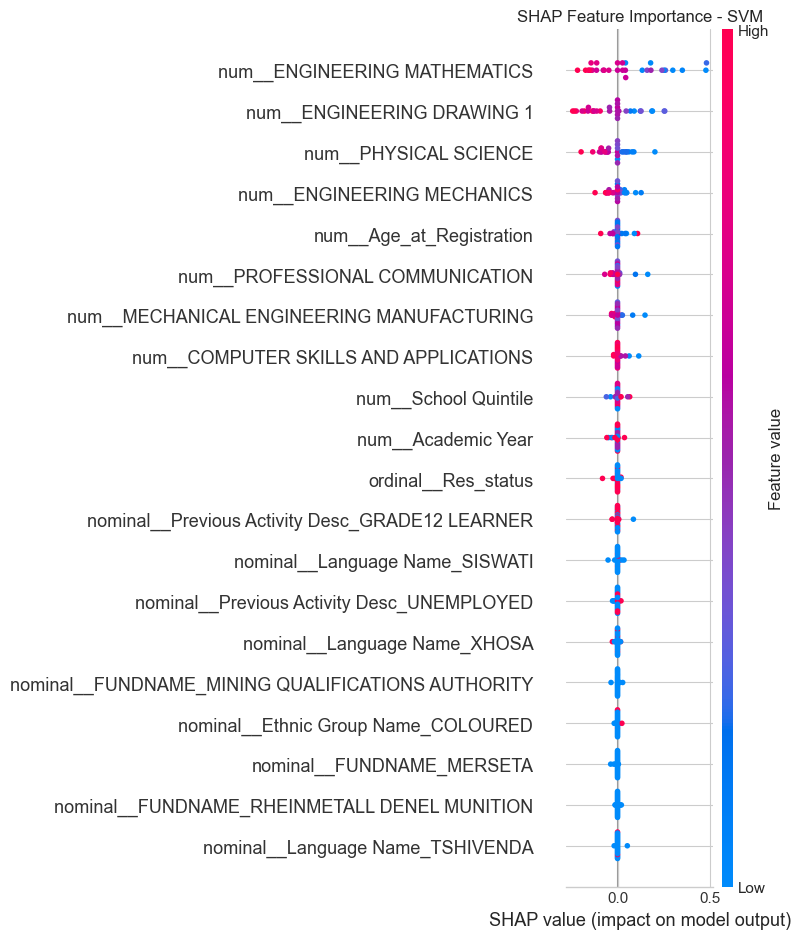


Top 10 Features by SHAP Importance (SVM):
  num__ENGINEERING MATHEMATICS: 0.1585
  num__ENGINEERING DRAWING 1: 0.1142
  num__PHYSICAL SCIENCE: 0.0603
  num__ENGINEERING MECHANICS: 0.0384
  num__Age_at_Registration: 0.0188
  num__PROFESSIONAL COMMUNICATION: 0.0176
  num__MECHANICAL ENGINEERING MANUFACTURING: 0.0153
  num__COMPUTER SKILLS AND APPLICATIONS: 0.0104
  num__School Quintile: 0.0095
  num__Academic Year: 0.0074


In [86]:
# SHAP ANALYSIS FOR SVM
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Get a sample of test data for SHAP (limit to 30 samples for speed)
sample_size = min(30, X_test_preprocessed.shape[0])
X_test_sample = X_test_preprocessed[:sample_size]

# Get feature names
feature_names = preprocessor_for_fs.get_feature_names_out()

print(f"Training data shape: {X_train_preprocessed.shape}")
print(f"Test data shape: {X_test_preprocessed.shape}")
print(f"Number of features: {X_train_preprocessed.shape[1]}")

# Create a simplified version of the SVM pipeline for SHAP
# We need to extract the classifier from the pipeline
svm_classifier = svm_model.named_steps['classifier']

# Create a function for SHAP to use
def predict_proba(X):
    return svm_classifier.predict_proba(X)

# Use KernelExplainer (works with any model)
print("Computing SHAP values... (this may take a moment)")

# Use a background dataset (use a subset of training data)
background_sample = X_train_preprocessed[:100]

# Create explainer
explainer = shap.KernelExplainer(predict_proba, background_sample)

# Compute SHAP values for test sample
shap_values = explainer.shap_values(X_test_sample, nsamples=100)

print(f"SHAP values shape: {len(shap_values)}")
if isinstance(shap_values, list):
    print(f"SHAP values list length: {len(shap_values)}")
    for i, sv in enumerate(shap_values):
        print(f"  Class {i} shape: {sv.shape}")
else:
    print(f"SHAP values shape: {shap_values.shape}")
print(f"Test sample shape: {X_test_sample.shape}")

# SHAP summary plot - for binary classification
if isinstance(shap_values, list) and len(shap_values) == 2:
    # For binary classification, use class 1 (At-Risk)
    shap_values_class1 = shap_values[1]
    
    # Create summary plot
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values_class1, X_test_sample, feature_names=feature_names, show=False)
    plt.title('SHAP Feature Importance - SVM (At-Risk Class)')
    plt.tight_layout()
    plt.show()
    
    # Bar plot of mean absolute SHAP values
    plt.figure(figsize=(10, 8))
    shap.summary_plot(shap_values_class1, X_test_sample, feature_names=feature_names, 
                     plot_type="bar", show=False)
    plt.title('SHAP Feature Importance (Mean |SHAP|) - SVM')
    plt.tight_layout()
    plt.show()
    
    # Get top features by mean absolute SHAP
    mean_abs_shap = np.mean(np.abs(shap_values_class1), axis=0)
    top_indices = np.argsort(mean_abs_shap)[-20:][::-1]
    
    print("\nTop 10 Features by SHAP Importance (SVM):")
    for idx in top_indices[:10]:
        print(f"  {feature_names[idx]}: {mean_abs_shap[idx]:.4f}")

elif isinstance(shap_values, np.ndarray) and shap_values.shape[-1] == 2:
    # Alternative format
    shap_values_class1 = shap_values[:, :, 1]
    
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values_class1, X_test_sample, feature_names=feature_names, show=False)
    plt.title('SHAP Feature Importance - SVM')
    plt.tight_layout()
    plt.show()
    
    # Mean absolute SHAP values
    mean_abs_shap = np.mean(np.abs(shap_values_class1), axis=0)
    top_indices = np.argsort(mean_abs_shap)[-20:][::-1]
    
    print("\nTop 10 Features by SHAP Importance (SVM):")
    for idx in top_indices[:10]:
        print(f"  {feature_names[idx]}: {mean_abs_shap[idx]:.4f}")
else:
    print("Unexpected SHAP values format. Please check the shape.")
    print(f"shap_values type: {type(shap_values)}")
    if isinstance(shap_values, list):
        for i, sv in enumerate(shap_values):
            print(f"  Class {i} shape: {sv.shape}")

# SVM with FS

SVM WITH FEATURE SELECTION PERFORMANCE:
Cross-validation Recall (mean): 0.8790 (+/- 0.0164)
Test Accuracy: 0.8971
Test Precision: 0.9571
Test Recall: 0.8590
Test F1-Score: 0.9054
Test ROC-AUC: 0.9759

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.95      0.89        58
           1       0.96      0.86      0.91        78

    accuracy                           0.90       136
   macro avg       0.90      0.90      0.90       136
weighted avg       0.90      0.90      0.90       136



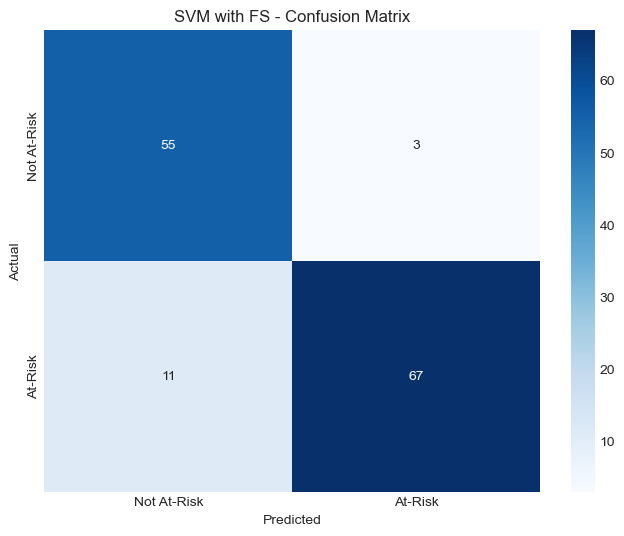

In [87]:
# SVM WITH FEATURE SELECTION
svm_with_fs = Pipeline([
    ('scaler', MinMaxScaler()),
    ('selector', SelectKBest(chi2, k=best_k)),
    ('classifier', SVC(
        kernel='rbf',
        probability=True,
        class_weight='balanced',
        random_state=42,
        C=1.0,
        gamma='scale'
    ))
])

# Fit
svm_with_fs.fit(X_train_preprocessed, y_train)

# Predictions
y_pred_svm_fs = svm_with_fs.predict(X_test_preprocessed)
y_prob_svm_fs = svm_with_fs.predict_proba(X_test_preprocessed)[:, 1]

# Cross-validation
cv_scores_svm_fs = cross_val_score(svm_with_fs, X_train_preprocessed, y_train, cv=5, scoring='recall')

print("SVM WITH FEATURE SELECTION PERFORMANCE:")
print(f"Cross-validation Recall (mean): {cv_scores_svm_fs.mean():.4f} (+/- {cv_scores_svm_fs.std():.4f})")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_svm_fs):.4f}")
print(f"Test Precision: {precision_score(y_test, y_pred_svm_fs):.4f}")
print(f"Test Recall: {recall_score(y_test, y_pred_svm_fs):.4f}")
print(f"Test F1-Score: {f1_score(y_test, y_pred_svm_fs):.4f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_prob_svm_fs):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm_fs))

# Confusion Matrix
cm_svm_fs = confusion_matrix(y_test, y_pred_svm_fs)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm_fs, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not At-Risk', 'At-Risk'],
            yticklabels=['Not At-Risk', 'At-Risk'])
plt.title('SVM with FS - Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# Random forest Model

RANDOM FOREST PERFORMANCE:
Cross-validation Recall (mean): 0.9745 (+/- 0.0162)
Test Accuracy: 0.9779
Test Precision: 1.0000
Test Recall: 0.9615
Test F1-Score: 0.9804
Test ROC-AUC: 0.9925

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        58
           1       1.00      0.96      0.98        78

    accuracy                           0.98       136
   macro avg       0.98      0.98      0.98       136
weighted avg       0.98      0.98      0.98       136



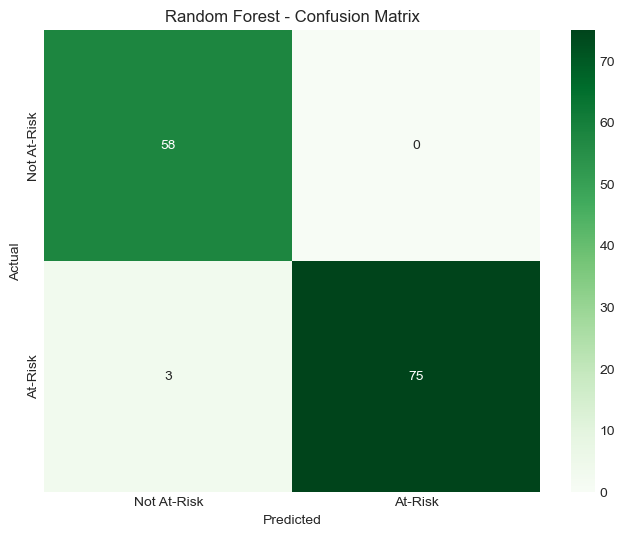

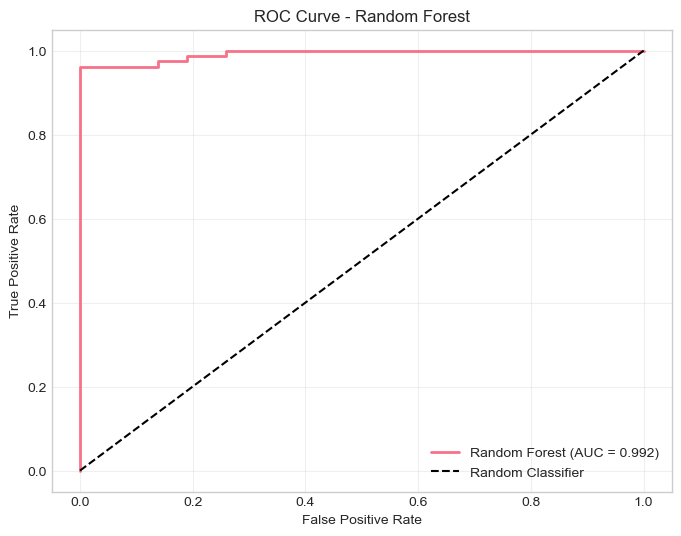

Raw Feature Importance (Top 20):


,Feature,Importance
4,num__ENGINEERING MATHEMATICS,0.238166
3,num__ENGINEERING DRAWING 1,0.225410
5,num__ENGINEERING MECHANICS,0.147110
7,num__PHYSICAL SCIENCE,0.143263
6,num__MECHANICAL ENGINEERING MANUFACTURING,0.070938
2,num__COMPUTER SKILLS AND APPLICATIONS,0.061701
8,num__PROFESSIONAL COMMUNICATION,0.051189
0,num__Academic Year,0.009448
1,num__School Quintile,0.009117
9,num__Age_at_Registration,0.007131


Aggregated Feature Importance (Top 20):


,Feature,Importance
0,ENGINEERING MATHEMATICS,0.238166
1,ENGINEERING DRAWING 1,0.225410
2,ENGINEERING MECHANICS,0.147110
3,PHYSICAL SCIENCE,0.143263
4,MECHANICAL ENGINEERING MANUFACTURING,0.070938
5,COMPUTER SKILLS AND APPLICATIONS,0.061701
6,PROFESSIONAL COMMUNICATION,0.051189
10,Language Name,0.011265
7,Academic Year,0.009448
8,School Quintile,0.009117


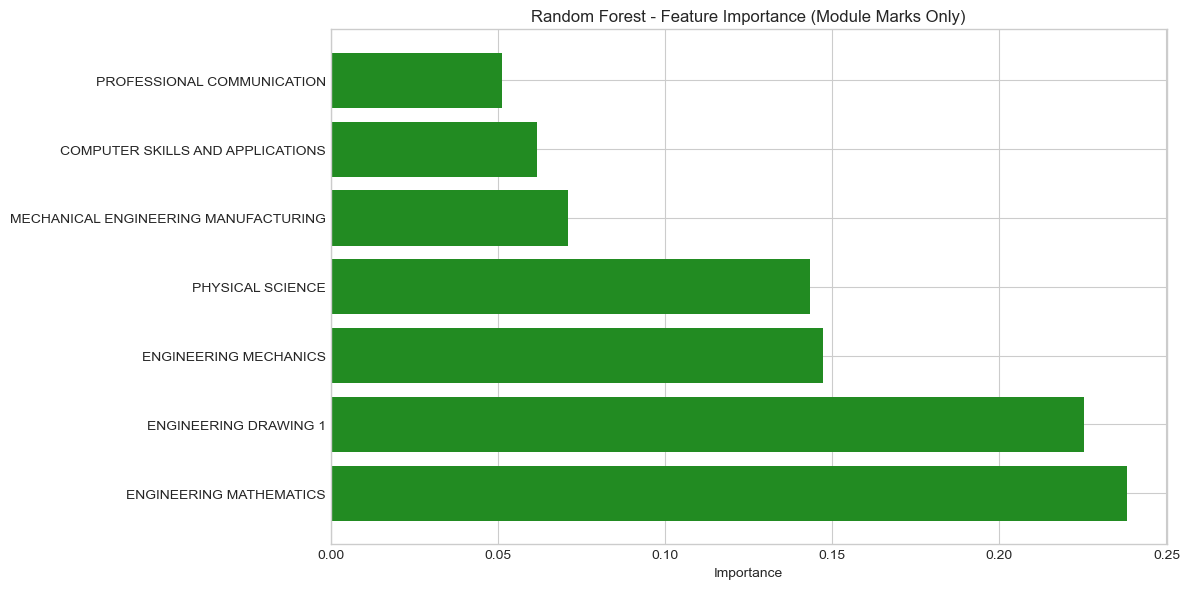


Random Forest - Module Feature Importance:


,Feature,Importance
0,ENGINEERING MATHEMATICS,0.238166
1,ENGINEERING DRAWING 1,0.225410
2,ENGINEERING MECHANICS,0.147110
3,PHYSICAL SCIENCE,0.143263
4,MECHANICAL ENGINEERING MANUFACTURING,0.070938
5,COMPUTER SKILLS AND APPLICATIONS,0.061701
6,PROFESSIONAL COMMUNICATION,0.051189


Computing permutation importance (this may take a few minutes)...
Permutation Importance (Raw):


,Feature,Importance,Std
4,num__ENGINEERING MATHEMATICS,0.086306,0.010510
3,num__ENGINEERING DRAWING 1,0.069427,0.009318
5,num__ENGINEERING MECHANICS,0.018790,0.005777
7,num__PHYSICAL SCIENCE,0.018790,0.007987
6,num__MECHANICAL ENGINEERING MANUFACTURING,0.008599,0.003782
8,num__PROFESSIONAL COMMUNICATION,0.006688,0.002229
2,num__COMPUTER SKILLS AND APPLICATIONS,0.004459,0.002919
1,num__School Quintile,0.003822,0.002776
0,num__Academic Year,0.002866,0.002229
12,ordinal__Funded,0.002548,0.001274



Permutation Importance (Aggregated):


,Feature,Importance,Std
0,ENGINEERING MATHEMATICS,0.086306,0.010510
1,ENGINEERING DRAWING 1,0.069427,0.009318
2,ENGINEERING MECHANICS,0.018790,0.005777
3,PHYSICAL SCIENCE,0.018790,0.007987
4,MECHANICAL ENGINEERING MANUFACTURING,0.008599,0.003782
5,PROFESSIONAL COMMUNICATION,0.006688,0.002229
6,COMPUTER SKILLS AND APPLICATIONS,0.004459,0.002919
7,School Quintile,0.003822,0.002776
8,Academic Year,0.002866,0.002229
10,Ethnic Group Name,0.002866,0.003104


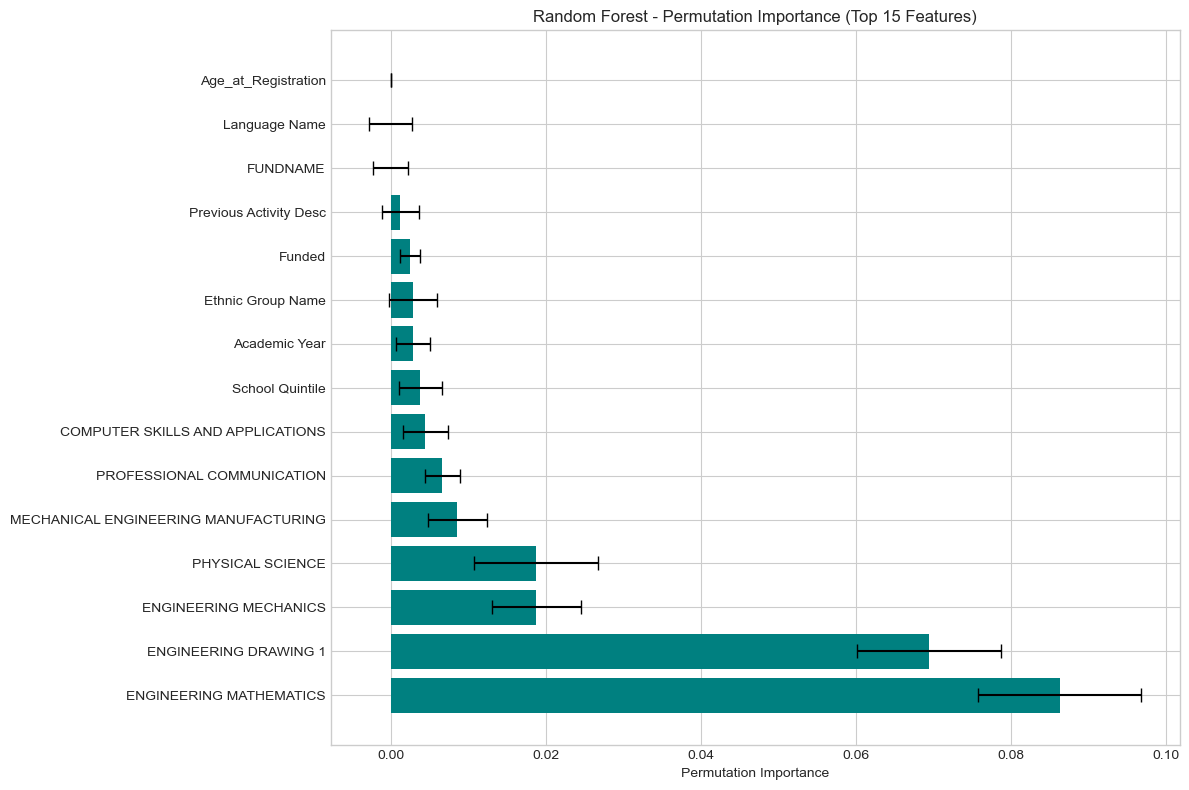


1. Top 5 features (aggregated importance):
   - ENGINEERING MATHEMATICS: 0.2382
   - ENGINEERING DRAWING 1: 0.2254
   - ENGINEERING MECHANICS: 0.1471
   - PHYSICAL SCIENCE: 0.1433
   - MECHANICAL ENGINEERING MANUFACTURING: 0.0709

2. Most important module: ENGINEERING MATHEMATICS (0.2382)

3. Random Forest Performance:
   - Recall: 0.9615
   - F1-Score: 0.9804
   - ROC-AUC: 0.9925


In [88]:
# RANDOM FOREST MODEL + FEATURE IMPORTANCE ANALYSIS

from sklearn.ensemble import RandomForestClassifier

# Train Random Forest with chosen parameters
rf_model = Pipeline([
    ('preprocess', rf_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])

# Fit Random Forest
rf_model.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Cross-validation
cv_scores_rf = cross_val_score(rf_model, X_train, y_train, cv=5, scoring='recall')

print("RANDOM FOREST PERFORMANCE:")
print(f"Cross-validation Recall (mean): {cv_scores_rf.mean():.4f} (+/- {cv_scores_rf.std():.4f})")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Test Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Test Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"Test F1-Score: {f1_score(y_test, y_pred_rf):.4f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

# Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Not At-Risk', 'At-Risk'],
            yticklabels=['Not At-Risk', 'At-Risk'])
plt.title('Random Forest - Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ROC Curve
fig, ax = plt.subplots(figsize=(8, 6))
fpr, tpr, _ = roc_curve(y_test, y_prob_rf)
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# RANDOM FOREST - FEATURE IMPORTANCE
rf_classifier = rf_model.named_steps['classifier']
raw_feature_names = rf_model.named_steps['preprocess'].get_feature_names_out()

# Raw importance
rf_raw_importance = pd.DataFrame({
    'Feature': raw_feature_names,
    'Importance': rf_classifier.feature_importances_
}).sort_values('Importance', ascending=False)

print("Raw Feature Importance (Top 20):")
display(rf_raw_importance.head(20))

# AGGREGATED FEATURE IMPORTANCE FOR RANDOM FOREST
rf_aggregated_importance = aggregate_feature_importance(rf_raw_importance)

print("Aggregated Feature Importance (Top 20):")
display(rf_aggregated_importance.head(20))

# RANDOM FOREST - MODULE IMPORTANCE ONLY
rf_module_features = [f for f in rf_aggregated_importance['Feature'] if f in module_cols]
rf_module_importance = rf_aggregated_importance[rf_aggregated_importance['Feature'].isin(rf_module_features)]
rf_module_importance = rf_module_importance.sort_values('Importance', ascending=False)

if len(rf_module_importance) > 0:
    plt.figure(figsize=(12, 6))
    plt.barh(rf_module_importance['Feature'], rf_module_importance['Importance'], color='forestgreen')
    plt.xlabel('Importance')
    plt.title('Random Forest - Feature Importance (Module Marks Only)')
    plt.tight_layout()
    plt.show()

    print("\nRandom Forest - Module Feature Importance:")
    display(rf_module_importance)

# RANDOM FOREST - PERMUTATION IMPORTANCE
from sklearn.inspection import permutation_importance

print("Computing permutation importance (this may take a few minutes)...")

X_train_transformed = rf_model.named_steps['preprocess'].transform(X_train)

perm_importance = permutation_importance(
    rf_classifier,
    X_train_transformed,
    y_train,
    n_repeats=10,
    random_state=42,
    scoring='recall',
    n_jobs=-1
)

rf_perm_importance = pd.DataFrame({
    'Feature': raw_feature_names,
    'Importance': perm_importance.importances_mean,
    'Std': perm_importance.importances_std
}).sort_values('Importance', ascending=False)

print("Permutation Importance (Raw):")
display(rf_perm_importance.head(20))

def aggregate_permutation_importance(perm_importance_df):
    """Aggregate permutation importance"""
    aggregated = {}
    stds = {}

    for feature, importance, std in zip(perm_importance_df['Feature'],
                                        perm_importance_df['Importance'],
                                        perm_importance_df['Std']):
        if '__' in feature:
            parts = feature.split('__', 1)
            prefix = parts[0]
            col_name = parts[1]

            if prefix == 'nominal':
                if '_' in col_name:
                    original_col = col_name.split('_')[0]
                else:
                    original_col = col_name
            else:
                original_col = col_name
        else:
            original_col = feature

        if original_col in aggregated:
            aggregated[original_col] += importance
            stds[original_col] = np.sqrt(stds.get(original_col, 0)**2 + std**2)
        else:
            aggregated[original_col] = importance
            stds[original_col] = std

    agg_df = pd.DataFrame({
        'Feature': list(aggregated.keys()),
        'Importance': list(aggregated.values()),
        'Std': list(stds.values())
    }).sort_values('Importance', ascending=False)

    return agg_df

rf_perm_agg = aggregate_permutation_importance(rf_perm_importance)

print("\nPermutation Importance (Aggregated):")
display(rf_perm_agg.head(20))

plt.figure(figsize=(12, 8))
top_perm = rf_perm_agg.head(15)
plt.barh(top_perm['Feature'], top_perm['Importance'],
         xerr=top_perm['Std'], color='teal', capsize=5)
plt.xlabel('Permutation Importance')
plt.title('Random Forest - Permutation Importance (Top 15 Features)')
plt.tight_layout()
plt.show()

# SUMMARY OF RANDOM FOREST FINDINGS
print(f"\n1. Top 5 features (aggregated importance):")
for i, row in rf_aggregated_importance.head(5).iterrows():
    print(f"   - {row['Feature']}: {row['Importance']:.4f}")

if len(rf_module_importance) > 0:
    print(f"\n2. Most important module: {rf_module_importance.iloc[0]['Feature']} ({rf_module_importance.iloc[0]['Importance']:.4f})")

print(f"\n3. Random Forest Performance:")
print(f"   - Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"   - F1-Score: {f1_score(y_test, y_pred_rf):.4f}")
print(f"   - ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")


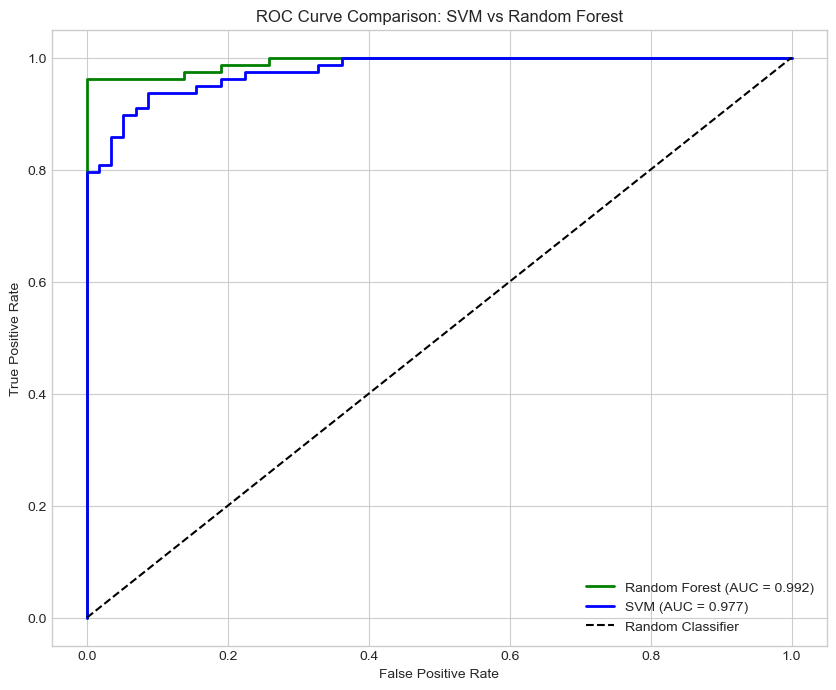

In [89]:
# Plot SVM and Random Forest ROC curves together for comparison
plt.figure(figsize=(10, 8))
fpr, tpr, _ = roc_curve(y_test, y_prob_rf)
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})', linewidth=2, color='green')
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
plt.plot(fpr_svm, tpr_svm, label=f'SVM (AUC = {roc_auc_score(y_test, y_prob_svm):.3f})', linewidth=2, color='blue')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison: SVM vs Random Forest')
plt.legend()

Transforming training data...
Computing permutation importance (this may take several minutes)...
Permutation importance completed in 9.73 seconds

SVM Permutation Importance (Raw - Top 20):


,Feature,Importance,Std
4,num__ENGINEERING MATHEMATICS,0.094586,0.006838
3,num__ENGINEERING DRAWING 1,0.086624,0.009426
7,num__PHYSICAL SCIENCE,0.029618,0.007676
9,num__Age_at_Registration,0.014968,0.007407
5,num__ENGINEERING MECHANICS,0.012102,0.005479
0,num__Academic Year,0.011465,0.005367
1,num__School Quintile,0.008917,0.003714
2,num__COMPUTER SKILLS AND APPLICATIONS,0.007006,0.002776
28,nominal__Language Name_XITSONGA,0.006369,0.000000
17,nominal__Language Name_ISINDEBELE,0.006051,0.000955


SVM Aggregated Permutation Importance (Top 20):


,Feature,Importance,Std
0,ENGINEERING MATHEMATICS,0.094586,0.006838
1,ENGINEERING DRAWING 1,0.086624,0.009426
2,PHYSICAL SCIENCE,0.029618,0.007676
8,Language Name,0.023885,0.004819
3,Age_at_Registration,0.014968,0.007407
4,ENGINEERING MECHANICS,0.012102,0.005479
5,Academic Year,0.011465,0.005367
6,School Quintile,0.008917,0.003714
9,Ethnic Group Name,0.008917,0.001274
13,Previous Activity Desc,0.007962,0.005165


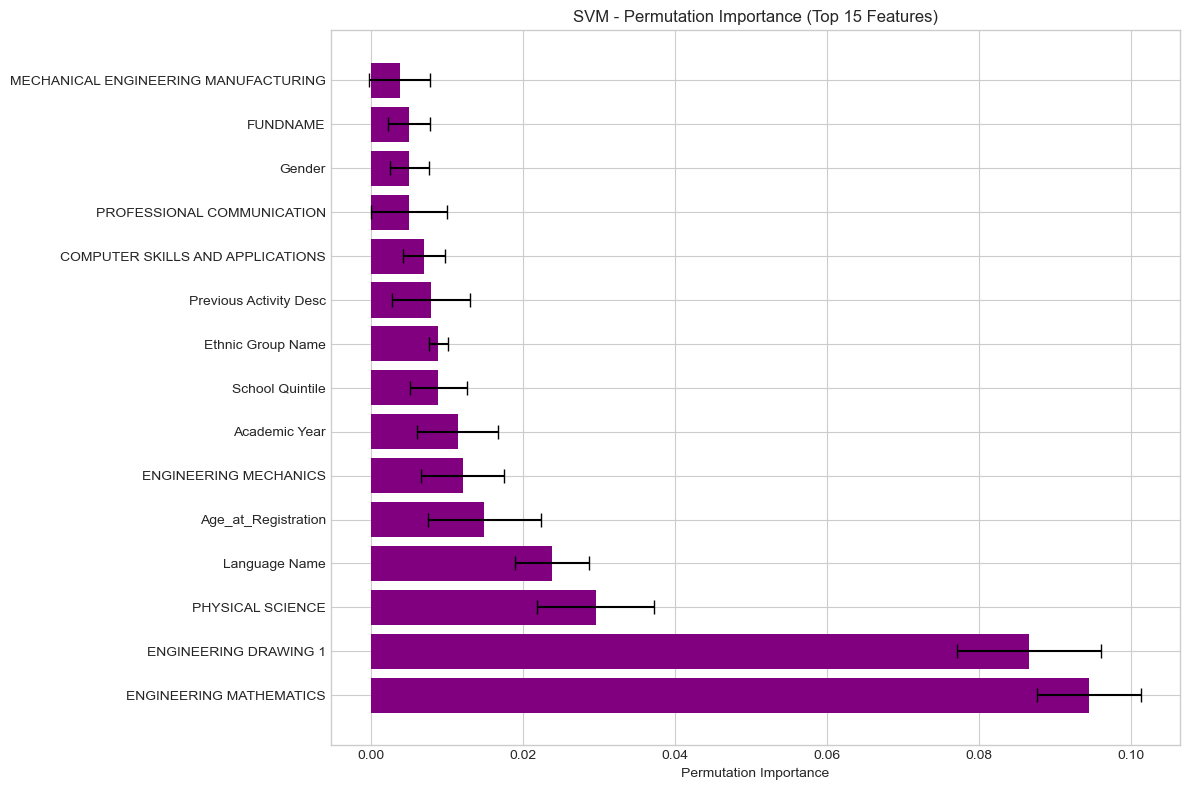


COMPARING SVM AND RANDOM FOREST IMPORTANCE
Feature Importance Comparison (SVM vs Random Forest):


,Feature,RF_Importance,SVM_Importance,Std,Avg_Importance
5,ENGINEERING MATHEMATICS,0.238166,0.094586,0.006838,0.166376
4,ENGINEERING DRAWING 1,0.225410,0.086624,0.009426,0.156017
13,PHYSICAL SCIENCE,0.143263,0.029618,0.007676,0.086440
6,ENGINEERING MECHANICS,0.147110,0.012102,0.005479,0.079606
12,MECHANICAL ENGINEERING MANUFACTURING,0.070938,0.003822,0.003978,0.037380
2,COMPUTER SKILLS AND APPLICATIONS,0.061701,0.007006,0.002776,0.034354
14,PROFESSIONAL COMMUNICATION,0.051189,0.005096,0.004975,0.028142
11,Language Name,0.011265,0.023885,0.004819,0.017575
1,Age_at_Registration,0.007131,0.014968,0.007407,0.011050
0,Academic Year,0.009448,0.011465,0.005367,0.010457


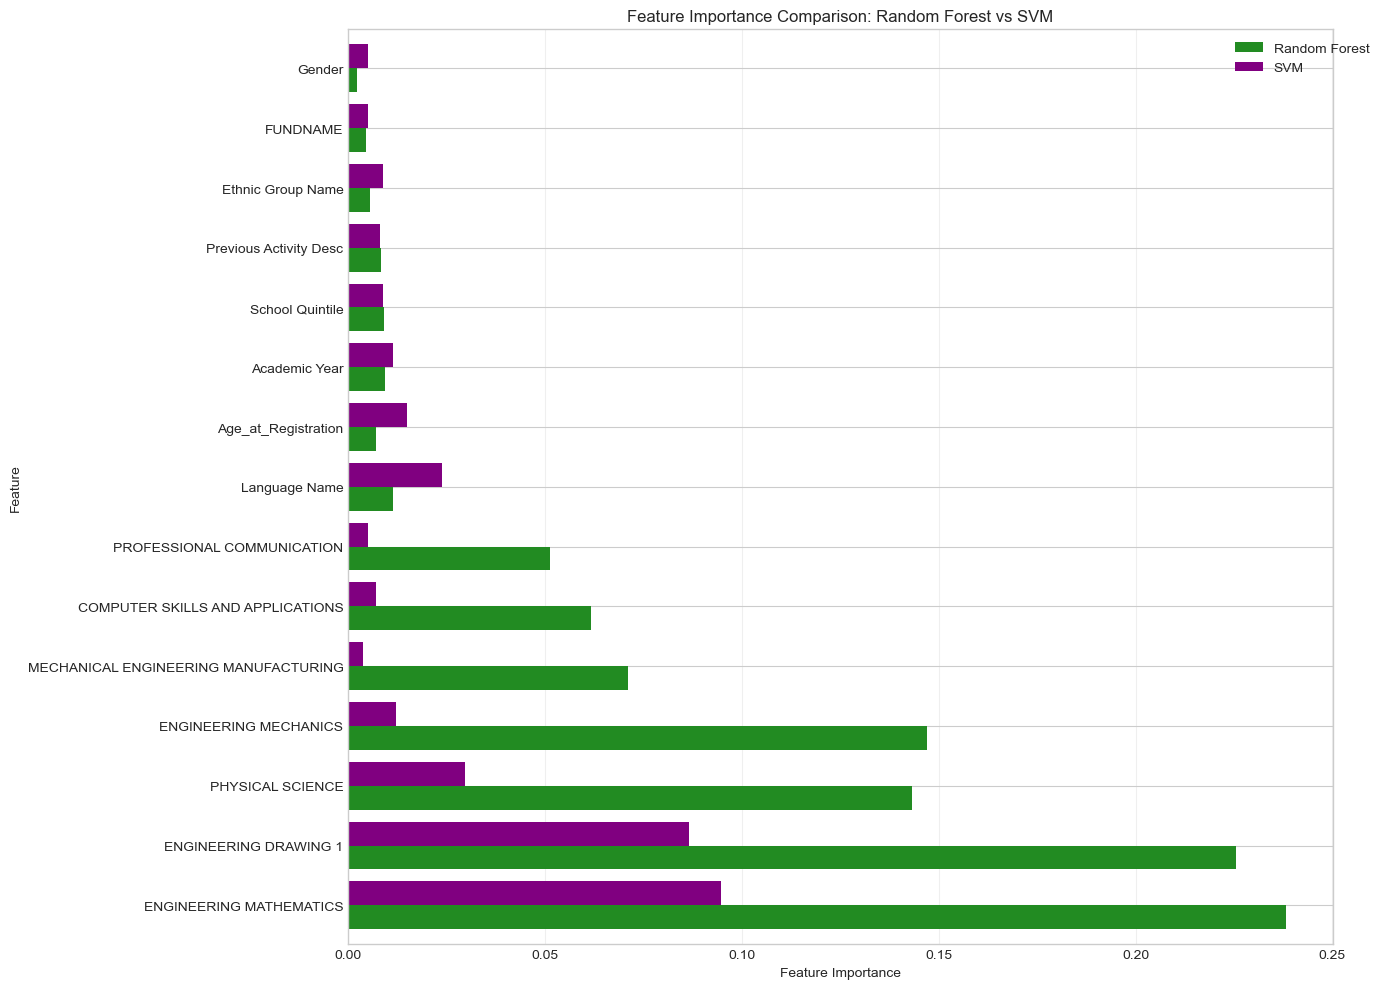

Training linear SVM for coefficient analysis...
Top 20 Features by Absolute Coefficient (Linear SVM):


,Feature,Coefficient,Abs_Coefficient
4,num__ENGINEERING MATHEMATICS,-2.223538,2.223538
3,num__ENGINEERING DRAWING 1,-1.742855,1.742855
7,num__PHYSICAL SCIENCE,-1.464552,1.464552
53,nominal__FUNDNAME_GAUTENG OFFICE OF THE PREMIER,-0.888099,0.888099
29,nominal__Ethnic Group Name_AFRICAN,-0.869056,0.869056
31,nominal__Ethnic Group Name_INDIAN,0.866242,0.866242
56,nominal__FUNDNAME_MERSETA,0.838897,0.838897
41,nominal__Previous Activity Desc_UNEMPLOYED,0.737916,0.737916
17,nominal__Language Name_ISINDEBELE,0.643270,0.643270
34,nominal__Country Name_ANGOLA,-0.634461,0.634461



Aggregated Coefficients (Top 20):


,Feature,Coefficient,Abs_Coefficient,Categories
6,Language Name,-9.409140e-15,3.844381,16
3,FUNDNAME,3.508305e-14,3.044542,20
4,Ethnic Group Name,6.750156e-14,2.484908,5
0,ENGINEERING MATHEMATICS,-2.223538e+00,2.223538,1
5,Previous Activity Desc,2.761680e-14,1.769855,6
1,ENGINEERING DRAWING 1,-1.742855e+00,1.742855,1
2,PHYSICAL SCIENCE,-1.464552e+00,1.464552,1
7,Country Name,9.120482e-14,1.268921,3
9,Student Type Description,9.120482e-14,0.714395,3
8,Res_status,-5.392730e-01,0.539273,1


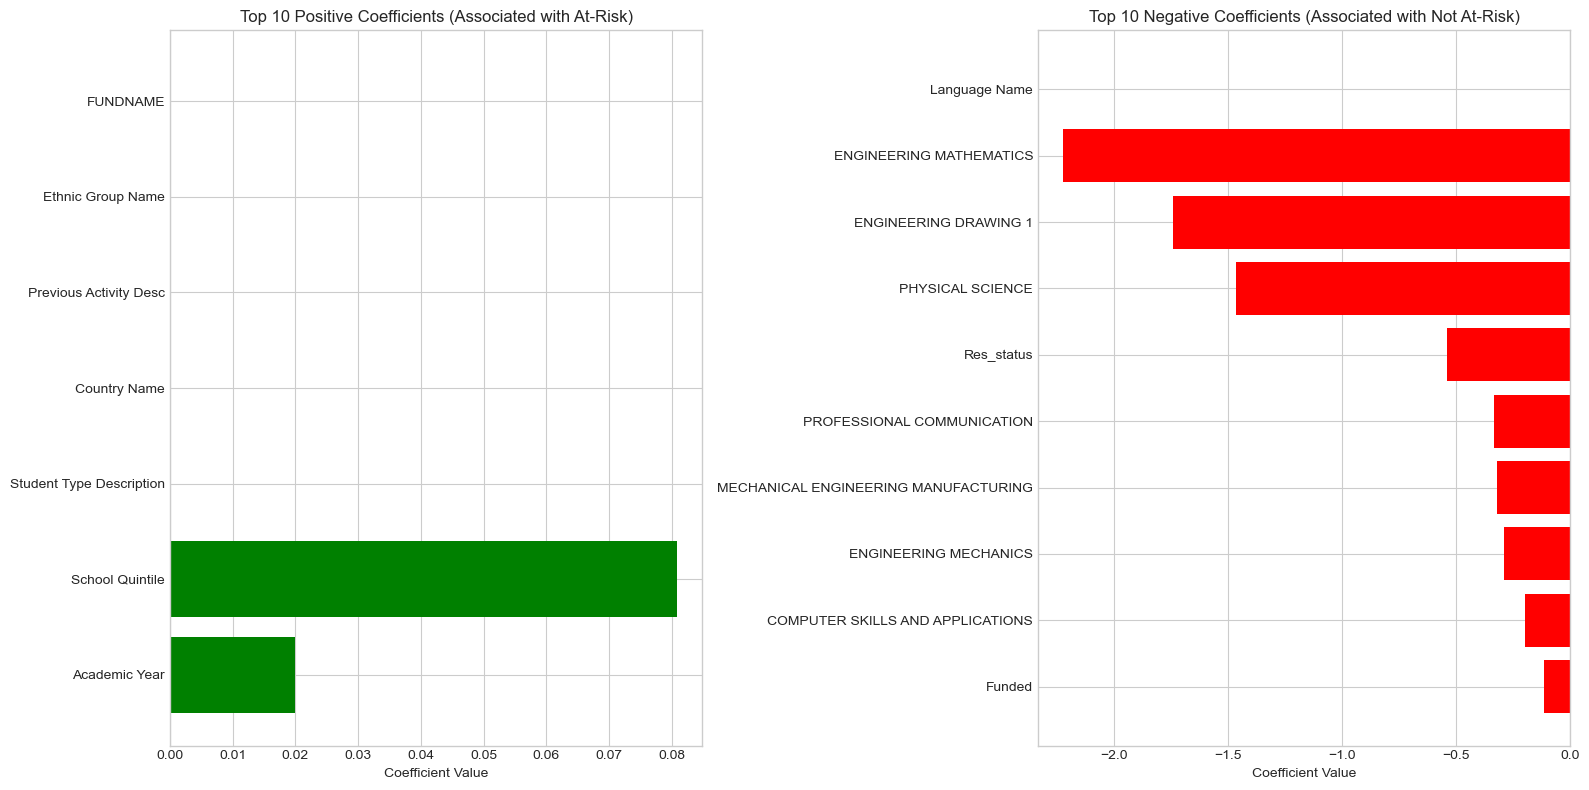


INTERPRETING SVM COEFFICIENTS:
----------------------------------------
Positive coefficients indicate features that INCREASE the probability
of being classified as 'At-Risk'.
Negative coefficients indicate features that DECREASE the probability
of being classified as 'At-Risk'.

Top 5 Features INCREASING At-Risk Probability:
   4. FUNDNAME: 0.0000
   5. Ethnic Group Name: 0.0000
   6. Previous Activity Desc: 0.0000
   8. Country Name: 0.0000
   10. Student Type Description: 0.0000

Top 5 Features DECREASING At-Risk Probability (Protective Factors):
   7. Language Name: -0.0000
   1. ENGINEERING MATHEMATICS: -2.2235
   2. ENGINEERING DRAWING 1: -1.7429
   3. PHYSICAL SCIENCE: -1.4646
   9. Res_status: -0.5393
Features consistently important in BOTH models (>1% importance):


,Feature,RF_Importance,SVM_Importance,Std,Avg_Importance
5,ENGINEERING MATHEMATICS,0.238166,0.094586,0.006838,0.166376
4,ENGINEERING DRAWING 1,0.225410,0.086624,0.009426,0.156017
13,PHYSICAL SCIENCE,0.143263,0.029618,0.007676,0.086440
6,ENGINEERING MECHANICS,0.147110,0.012102,0.005479,0.079606
11,Language Name,0.011265,0.023885,0.004819,0.017575


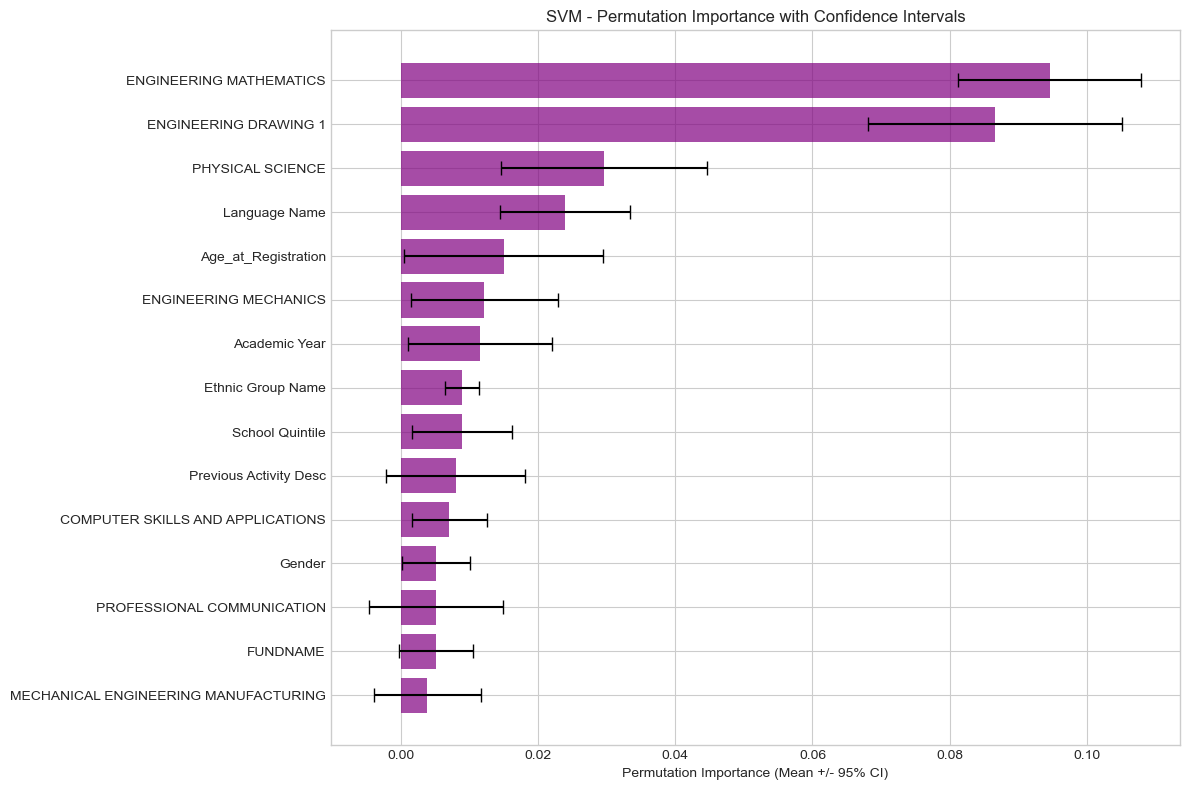


1. Top 5 features (permutation importance):
   - ENGINEERING MATHEMATICS: 0.0946 (+/-0.0068)
   - ENGINEERING DRAWING 1: 0.0866 (+/-0.0094)
   - PHYSICAL SCIENCE: 0.0296 (+/-0.0077)
   - Language Name: 0.0239 (+/-0.0048)
   - Age_at_Registration: 0.0150 (+/-0.0074)

2. Most important module: ENGINEERING MATHEMATICS (0.0946)

3. Strongest risk factor: FUNDNAME (0.0000)
   Strongest protective factor: Language Name (-0.0000)

4. Features consistently important in both models: 5
   Top consistent feature: ENGINEERING MATHEMATICS

5. SVM Performance:
   - Recall: 0.8462
   - F1-Score: 0.9041
   - ROC-AUC: 0.9768


In [90]:
from sklearn.inspection import permutation_importance
from sklearn.svm import SVC
import time

# PERMUTATION IMPORTANCE FOR SVM

# Get transformed training data
print("Transforming training data...")
X_train_transformed = svm_model.named_steps['preprocess'].transform(X_train)
X_test_transformed = svm_model.named_steps['preprocess'].transform(X_test)

# Get the SVM classifier
svm_classifier = svm_model.named_steps['classifier']

# Compute permutation importance
print("Computing permutation importance (this may take several minutes)...")
start_time = time.time()

perm_importance_svm = permutation_importance(
    svm_classifier,
    X_train_transformed,
    y_train,
    n_repeats=10,
    random_state=42,
    scoring='recall',
    n_jobs=-1
)

end_time = time.time()
print(f"Permutation importance completed in {end_time - start_time:.2f} seconds")

svm_raw_importance = pd.DataFrame({
    'Feature': raw_feature_names,
    'Importance': perm_importance_svm.importances_mean,
    'Std': perm_importance_svm.importances_std
}).sort_values('Importance', ascending=False)

print("\nSVM Permutation Importance (Raw - Top 20):")
display(svm_raw_importance.head(20))

# SVM - AGGREGATED PERMUTATION IMPORTANCE
svm_aggregated_importance = aggregate_permutation_importance(svm_raw_importance)

print("SVM Aggregated Permutation Importance (Top 20):")
display(svm_aggregated_importance.head(20))

plt.figure(figsize=(12, 8))
top_svm_perm = svm_aggregated_importance.head(15)
plt.barh(top_svm_perm['Feature'], top_svm_perm['Importance'],
         xerr=top_svm_perm['Std'], color='purple', capsize=5)
plt.xlabel('Permutation Importance')
plt.title('SVM - Permutation Importance (Top 15 Features)')
plt.tight_layout()
plt.show()

# COMPARE SVM VS RANDOM FOREST IMPORTANCE
print("\n" + "="*60)
print("COMPARING SVM AND RANDOM FOREST IMPORTANCE")
print("="*60)

all_importance = pd.merge(
    rf_aggregated_importance.rename(columns={'Importance': 'RF_Importance'}),
    svm_aggregated_importance.rename(columns={'Importance': 'SVM_Importance'}),
    on='Feature',
    how='outer'
).fillna(0)

all_importance['Avg_Importance'] = (
    all_importance['RF_Importance'] + all_importance['SVM_Importance']
) / 2

all_importance = all_importance.sort_values('Avg_Importance', ascending=False)

print("Feature Importance Comparison (SVM vs Random Forest):")
display(all_importance.head(20))

# VISUALIZE BOTH MODELS SIDE BY SIDE
top15_features = all_importance.head(15)['Feature'].tolist()
comparison_plot_data = all_importance[all_importance['Feature'].isin(top15_features)]
comparison_plot_data = comparison_plot_data.set_index('Feature')[['RF_Importance', 'SVM_Importance']]

fig, ax = plt.subplots(figsize=(14, 10))
comparison_plot_data.plot(kind='barh', ax=ax,
                         color=['forestgreen', 'purple'],
                         width=0.8)
ax.set_xlabel('Feature Importance')
ax.set_title('Feature Importance Comparison: Random Forest vs SVM')
ax.legend(['Random Forest', 'SVM'], bbox_to_anchor=(1.05, 1))
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

# SVM COEFFICIENT-BASED IMPORTANCE (FOR LINEAR KERNEL)
print("Training linear SVM for coefficient analysis...")
linear_svm = Pipeline([
    ('preprocess', svm_preprocessor),
    ('classifier', SVC(
        kernel='linear',
        class_weight='balanced',
        random_state=42,
        C=1.0
    ))
])

linear_svm.fit(X_train, y_train)

svm_coefficients = linear_svm.named_steps['classifier'].coef_[0]
raw_feature_names = linear_svm.named_steps['preprocess'].get_feature_names_out()

svm_coef_importance = pd.DataFrame({
    'Feature': raw_feature_names,
    'Coefficient': svm_coefficients,
    'Abs_Coefficient': np.abs(svm_coefficients)
}).sort_values('Abs_Coefficient', ascending=False)

print("Top 20 Features by Absolute Coefficient (Linear SVM):")
display(svm_coef_importance.head(20))

def aggregate_coefficients(coef_df):
    """Aggregate coefficients by original feature name"""
    aggregated = {}

    for feature, coef, abs_coef in zip(coef_df['Feature'],
                                       coef_df['Coefficient'],
                                       coef_df['Abs_Coefficient']):
        if '__' in feature:
            parts = feature.split('__', 1)
            prefix = parts[0]
            col_name = parts[1]

            if prefix == 'nominal':
                if '_' in col_name:
                    original_col = col_name.split('_')[0]
                else:
                    original_col = col_name
            else:
                original_col = col_name
        else:
            original_col = feature

        if original_col in aggregated:
            aggregated[original_col]['Coefficient'] += coef
            aggregated[original_col]['Abs_Coefficient'] += abs_coef
            aggregated[original_col]['Count'] += 1
        else:
            aggregated[original_col] = {
                'Coefficient': coef,
                'Abs_Coefficient': abs_coef,
                'Count': 1
            }

    agg_df = pd.DataFrame({
        'Feature': list(aggregated.keys()),
        'Coefficient': [v['Coefficient'] for v in aggregated.values()],
        'Abs_Coefficient': [v['Abs_Coefficient'] for v in aggregated.values()],
        'Categories': [v['Count'] for v in aggregated.values()]
    }).sort_values('Abs_Coefficient', ascending=False)

    return agg_df

svm_coef_agg = aggregate_coefficients(svm_coef_importance)

print("\nAggregated Coefficients (Top 20):")
display(svm_coef_agg.head(20))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

positive_coef = svm_coef_agg[svm_coef_agg['Coefficient'] > 0].head(10)
axes[0].barh(positive_coef['Feature'], positive_coef['Coefficient'], color='green')
axes[0].set_xlabel('Coefficient Value')
axes[0].set_title('Top 10 Positive Coefficients (Associated with At-Risk)')
axes[0].invert_yaxis()

negative_coef = svm_coef_agg[svm_coef_agg['Coefficient'] < 0].head(10)
axes[1].barh(negative_coef['Feature'], negative_coef['Coefficient'], color='red')
axes[1].set_xlabel('Coefficient Value')
axes[1].set_title('Top 10 Negative Coefficients (Associated with Not At-Risk)')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print("\nINTERPRETING SVM COEFFICIENTS:")
print("-" * 40)
print("Positive coefficients indicate features that INCREASE the probability")
print("of being classified as 'At-Risk'.")
print("Negative coefficients indicate features that DECREASE the probability")
print("of being classified as 'At-Risk'.")

print("\nTop 5 Features INCREASING At-Risk Probability:")
for i, row in positive_coef.head(5).iterrows():
    print(f"   {i+1}. {row['Feature']}: {row['Coefficient']:.4f}")

print("\nTop 5 Features DECREASING At-Risk Probability (Protective Factors):")
for i, row in negative_coef.head(5).iterrows():
    print(f"   {i+1}. {row['Feature']}: {row['Coefficient']:.4f}")

# CONSISTENCY ANALYSIS: SVM vs RANDOM FOREST
consistent_svm_rf = all_importance[
    (all_importance['RF_Importance'] > 0.01) &
    (all_importance['SVM_Importance'] > 0.01)
].sort_values('Avg_Importance', ascending=False)

print("Features consistently important in BOTH models (>1% importance):")
display(consistent_svm_rf.head(20))

# SVM PERMUTATION IMPORTANCE WITH CONFIDENCE INTERVALS
plt.figure(figsize=(12, 8))
top_svm_perm_ci = svm_aggregated_importance.head(15)
top_svm_perm_ci = top_svm_perm_ci.sort_values('Importance', ascending=True)

plt.barh(top_svm_perm_ci['Feature'], top_svm_perm_ci['Importance'],
         xerr=top_svm_perm_ci['Std'] * 1.96,
         color='purple', capsize=5, alpha=0.7)
plt.xlabel('Permutation Importance (Mean +/- 95% CI)')
plt.title('SVM - Permutation Importance with Confidence Intervals')
plt.tight_layout()
plt.show()

# SUMMARY OF SVM FINDINGS
print(f"\n1. Top 5 features (permutation importance):")
for i, row in svm_aggregated_importance.head(5).iterrows():
    print(f"   - {row['Feature']}: {row['Importance']:.4f} (+/-{row['Std']:.4f})")

svm_module_features = [f for f in svm_aggregated_importance['Feature'] if f in module_cols]
svm_module_importance = svm_aggregated_importance[
    svm_aggregated_importance['Feature'].isin(svm_module_features)
].sort_values('Importance', ascending=False)

if len(svm_module_importance) > 0:
    print(f"\n2. Most important module: {svm_module_importance.iloc[0]['Feature']} ({svm_module_importance.iloc[0]['Importance']:.4f})")

if len(positive_coef) > 0:
    print(f"\n3. Strongest risk factor: {positive_coef.iloc[0]['Feature']} ({positive_coef.iloc[0]['Coefficient']:.4f})")
if len(negative_coef) > 0:
    print(f"   Strongest protective factor: {negative_coef.iloc[0]['Feature']} ({negative_coef.iloc[0]['Coefficient']:.4f})")

consistent_count = len(consistent_svm_rf)
print(f"\n4. Features consistently important in both models: {consistent_count}")
if consistent_count > 0:
    print(f"   Top consistent feature: {consistent_svm_rf.iloc[0]['Feature']}")

print(f"\n5. SVM Performance:")
print(f"   - Recall: {recall_score(y_test, y_pred_svm):.4f}")
print(f"   - F1-Score: {f1_score(y_test, y_pred_svm):.4f}")
print(f"   - ROC-AUC: {roc_auc_score(y_test, y_prob_svm):.4f}")


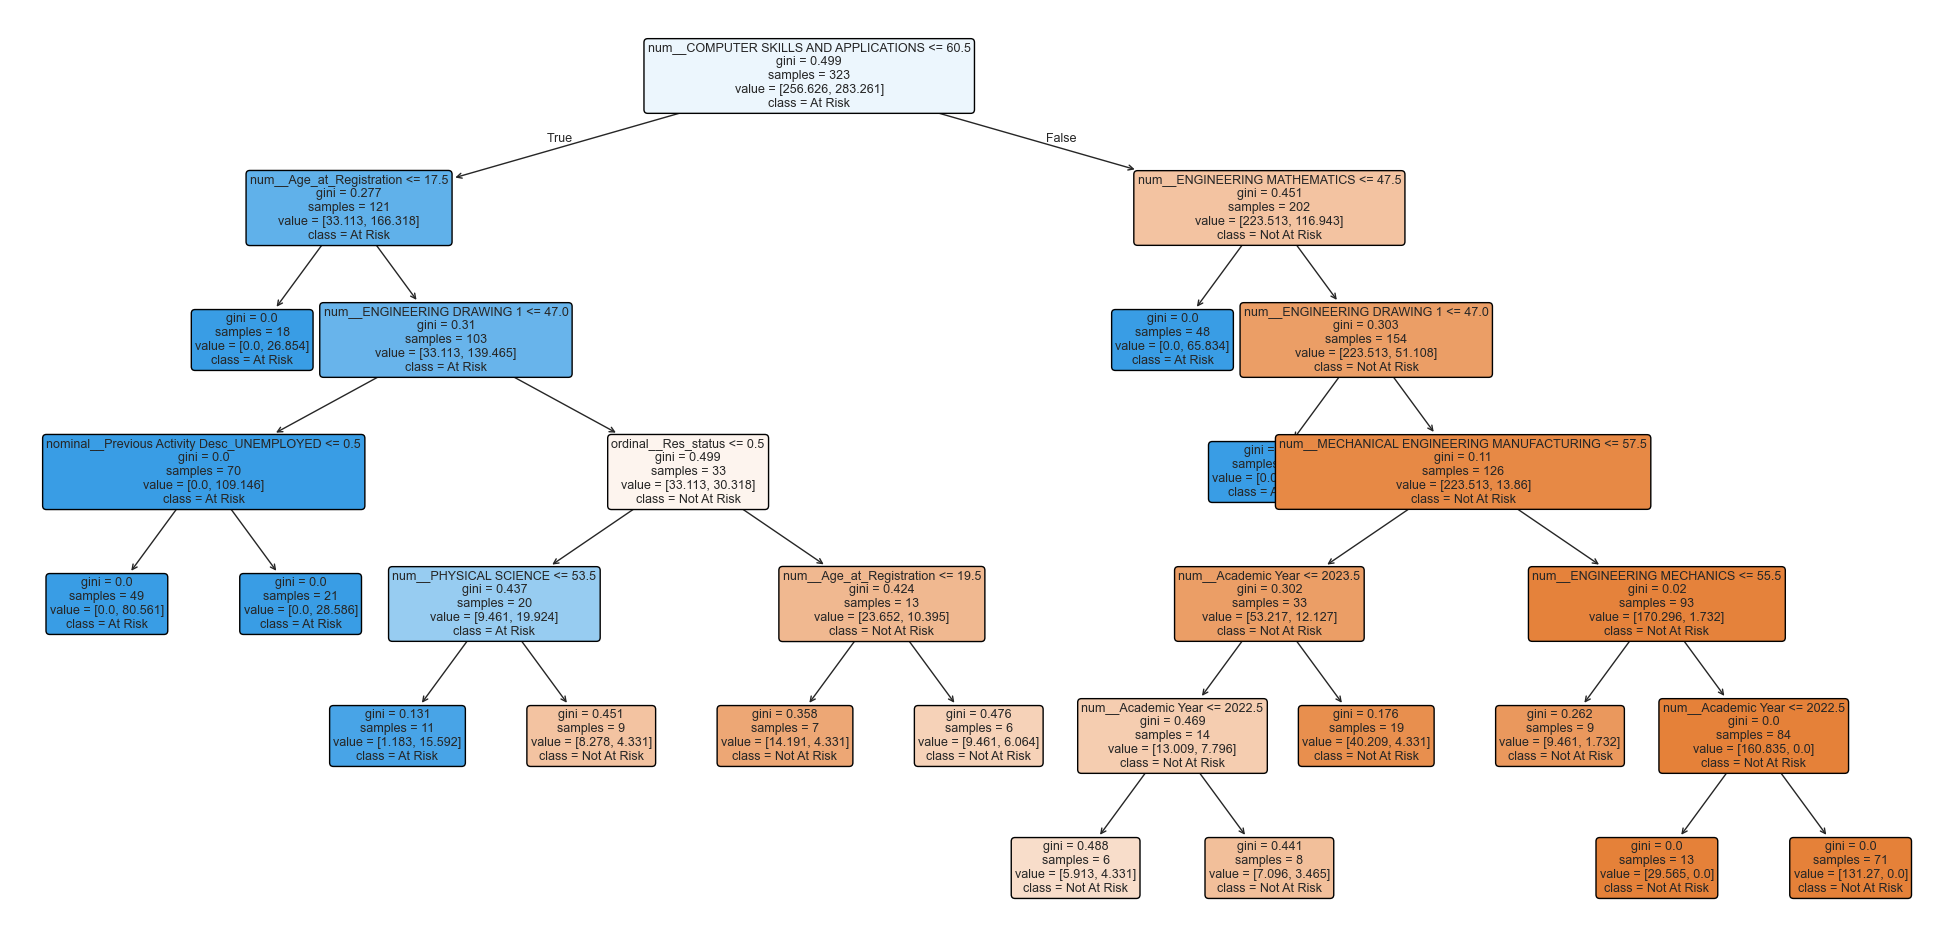

In [91]:
# Visualize the best tree from Random Forest model
estimator_depths = [
    tree.tree_.max_depth
    for tree in rf_model.named_steps["classifier"].estimators_
]

best_tree = np.argmin(estimator_depths)

plt.figure(figsize=(25,12))

plot_tree(
    rf_model.named_steps["classifier"].estimators_[best_tree],
    feature_names=raw_feature_names,
    class_names=["Not At Risk","At Risk"],
    filled=True,
    rounded=True,
    max_depth=9,
    fontsize=9
)

plt.show()

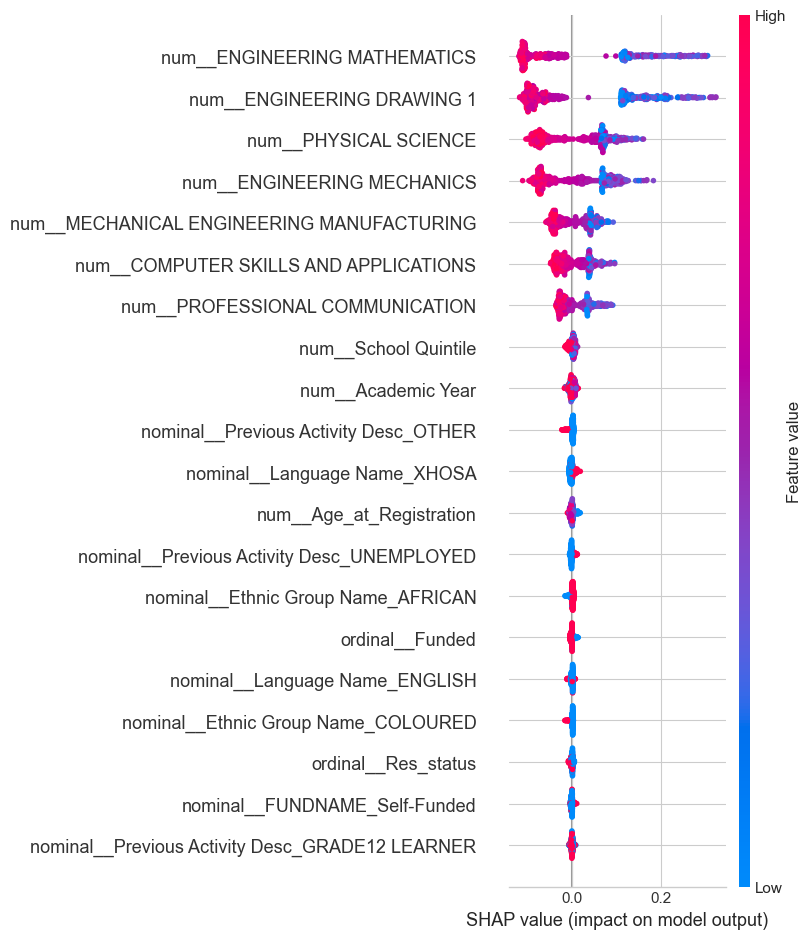

In [92]:
# SHAP EXPLANATION FOR RANDOM FOREST MODEL
import shap

X_processed = rf_model.named_steps["preprocess"].transform(X_train)

explainer = shap.TreeExplainer(
    rf_model.named_steps["classifier"]
)

shap_values = explainer.shap_values(X_processed)

shap.summary_plot(
    shap_values[:, :, 1],
    X_processed,
    feature_names=raw_feature_names
)

Running LOOCV for Random Forest (680 folds)... this may take a while.
Done in 5.0 minutes.

LOOCV PERFORMANCE — Random Forest
Accuracy : 0.9647
Precision: 0.9670
Recall   : 0.9719
F1-Score : 0.9695

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.95      0.96       288
           1       0.97      0.97      0.97       392

    accuracy                           0.96       680
   macro avg       0.96      0.96      0.96       680
weighted avg       0.96      0.96      0.96       680



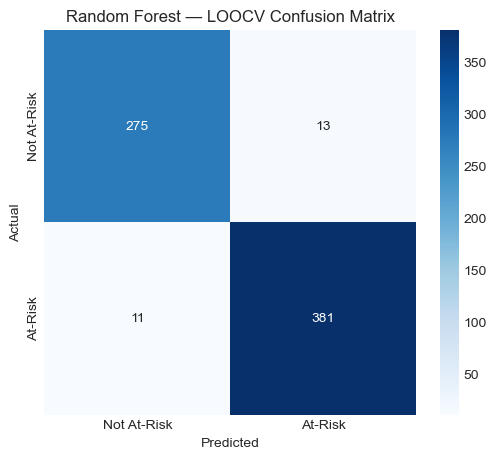

Running LOOCV for SVM (680 folds)... this may take a while.
Done in 0.6 minutes.

LOOCV PERFORMANCE — SVM
Accuracy : 0.9265
Precision: 0.9647
Recall   : 0.9056
F1-Score : 0.9342

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.95      0.92       288
           1       0.96      0.91      0.93       392

    accuracy                           0.93       680
   macro avg       0.92      0.93      0.93       680
weighted avg       0.93      0.93      0.93       680



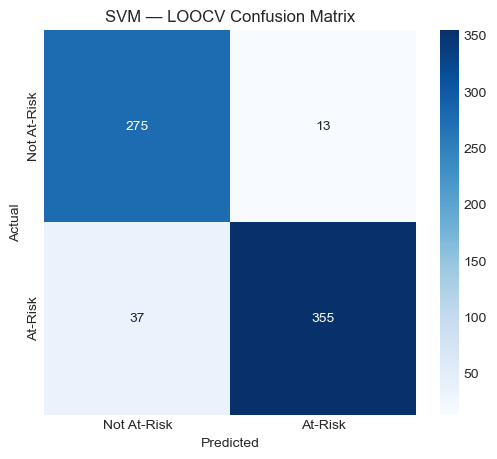

In [93]:
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
import time

loo = LeaveOneOut()

def run_loocv(pipeline, X, y, model_name):
    """
    Leave-One-Out CV: refits `pipeline` on all but one sample, 793 times,
    and collects the held-out prediction for every sample.
    """
    print(f"Running LOOCV for {model_name} ({len(X)} folds)... this may take a while.")
    start = time.time()

    y_pred_loo = cross_val_predict(pipeline, X, y, cv=loo, method='predict', n_jobs=-1)

    elapsed = time.time() - start
    print(f"Done in {elapsed/60:.1f} minutes.\n")

    print(f"LOOCV PERFORMANCE — {model_name}")
    print(f"Accuracy : {accuracy_score(y, y_pred_loo):.4f}")
    print(f"Precision: {precision_score(y, y_pred_loo):.4f}")
    print(f"Recall   : {recall_score(y, y_pred_loo):.4f}")
    print(f"F1-Score : {f1_score(y, y_pred_loo):.4f}")
    print("\nClassification Report:")
    print(classification_report(y, y_pred_loo))

    cm = confusion_matrix(y, y_pred_loo)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Not At-Risk', 'At-Risk'],
                yticklabels=['Not At-Risk', 'At-Risk'])
    plt.title(f'{model_name} — LOOCV Confusion Matrix')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

    return y_pred_loo


# --- Random Forest: fast, no extra tuning needed ---
y_pred_rf_loo = run_loocv(rf_model, X, y, "Random Forest")

# --- SVM: this is the slow one (internal Platt-scaling calibration per fit) ---
y_pred_svm_loo = run_loocv(svm_model, X, y, "SVM")

## Final Model Comparison: SVM vs. Random Forest

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Recall
0,SVM,0.8971,0.9706,0.8462,0.9041,0.9768,0.9046
1,Random Forest,0.9779,1.0000,0.9615,0.9804,0.9925,0.9745


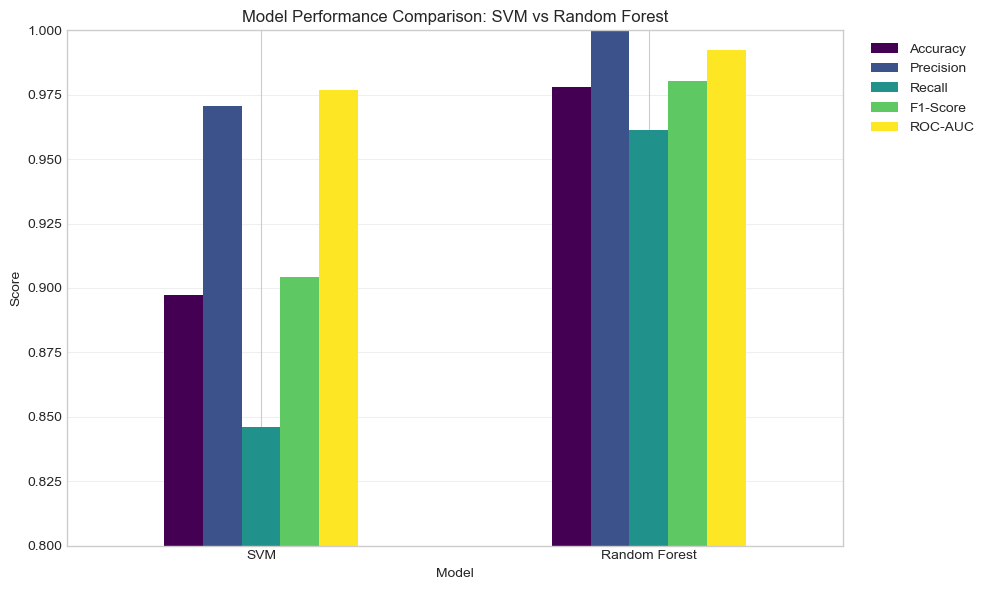


Best performing model (by recall): Random Forest (Recall: 0.9615)


In [94]:
# FINAL MODEL COMPARISON: SVM vs RANDOM FOREST

comparison_final = pd.DataFrame({
    'Model': ['SVM', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        precision_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_rf)
    ],
    'Recall': [
        recall_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_rf)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_rf)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_svm),
        roc_auc_score(y_test, y_prob_rf)
    ],
    'CV Recall': [
        cv_scores_svm.mean(),
        cv_scores_rf.mean()
    ]
}).round(4)

display(comparison_final)

# Visual comparison
fig, ax = plt.subplots(figsize=(10, 6))
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
comparison_final.set_index('Model')[metrics].plot(kind='bar', ax=ax, colormap='viridis', rot=0)
ax.set_title('Model Performance Comparison: SVM vs Random Forest')
ax.set_ylabel('Score')
ax.set_ylim(0.8, 1.0)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

best_recall_idx = comparison_final['Recall'].idxmax()
print(f"\nBest performing model (by recall): {comparison_final.loc[best_recall_idx, 'Model']} "
      f"(Recall: {comparison_final.loc[best_recall_idx, 'Recall']:.4f})")


# Module Analysis

In [117]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from itertools import combinations

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

PASS_MARK = 50

MODULES = [
    'COMPUTER SKILLS AND APPLICATIONS',
    'ENGINEERING DRAWING 1',
    'ENGINEERING MATHEMATICS',
    'ENGINEERING MECHANICS',
    'MECHANICAL ENGINEERING MANUFACTURING',
    'PHYSICAL SCIENCE',
    'PROFESSIONAL COMMUNICATION',
]

SHORT = {
    'COMPUTER SKILLS AND APPLICATIONS':       'Comp Skills',
    'ENGINEERING DRAWING 1':                  'Eng Drawing',
    'ENGINEERING MATHEMATICS':                'Eng Maths',
    'ENGINEERING MECHANICS':                  'Eng Mechanics',
    'MECHANICAL ENGINEERING MANUFACTURING':   'Mech Manuf',
    'PHYSICAL SCIENCE':                       'Phys Science',
    'PROFESSIONAL COMMUNICATION':             'Prof Comm',
}

In [118]:
df = pd.read_excel('../../Enrol_model.xlsx')

keep = ['Academic Year', 'At_Risk', 'Gender', 'Ethnic Group Name',
        'Funded', 'Res_status'] + MODULES
keep = [c for c in keep if c in df.columns]
df = df[keep].copy()

if df['At_Risk'].dtype != object:
    df['At_Risk'] = df['At_Risk'].map({1: 'Yes', 0: 'No'})

print('Shape:', df.shape)
print('Academic years:', sorted(df['Academic Year'].unique()))
print('At_Risk distribution:')
print(df['At_Risk'].value_counts())

Shape: (725, 12)
Academic years: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
At_Risk distribution:
At_Risk
Yes    422
No     303
Name: count, dtype: int64


In [119]:
# Define the seven modules
MODULES = [
    'COMPUTER SKILLS AND APPLICATIONS',
    'ENGINEERING DRAWING 1',
    'ENGINEERING MATHEMATICS',
    'ENGINEERING MECHANICS',
    'MECHANICAL ENGINEERING MANUFACTURING',
    'PHYSICAL SCIENCE',
    'PROFESSIONAL COMMUNICATION',
]

# Count how many modules each student is registered for
student_module_counts = df[MODULES].notna().sum(axis=1)

# Show distribution BEFORE dropping
print("BEFORE dropping:")
print(f"Total students: {len(df)}")
print(student_module_counts.value_counts().sort_index())

# Keep only students registered for all 7 modules
df = df[student_module_counts == 7].copy()

# Reset index (optional but recommended)
df = df.reset_index(drop=True)

# Show distribution AFTER dropping
print("\nAFTER dropping:")
print(f"Total students: {len(df)}")
print(df[MODULES].notna().sum(axis=1).value_counts().sort_index())

# Verify all remaining students have all 7 modules
assert df[MODULES].notna().all(axis=1).all(), "Some students still missing modules!"
print("\n✅ All remaining students are registered for all 7 modules.")

BEFORE dropping:
Total students: 725
1      1
2      1
3      2
4     11
5      6
6     24
7    680
Name: count, dtype: int64

AFTER dropping:
Total students: 680
7    680
Name: count, dtype: int64

✅ All remaining students are registered for all 7 modules.


Overall module failure rates (2022–2025):
                              Module  N students  N failed  Failure rate (%)  Missing marks
             ENGINEERING MATHEMATICS         680       257              37.8              0
               ENGINEERING DRAWING 1         680       256              37.6              0
               ENGINEERING MECHANICS         680       209              30.7              0
                    PHYSICAL SCIENCE         680       145              21.3              0
MECHANICAL ENGINEERING MANUFACTURING         680       110              16.2              0
          PROFESSIONAL COMMUNICATION         680        80              11.8              0
    COMPUTER SKILLS AND APPLICATIONS         680        76              11.2              0


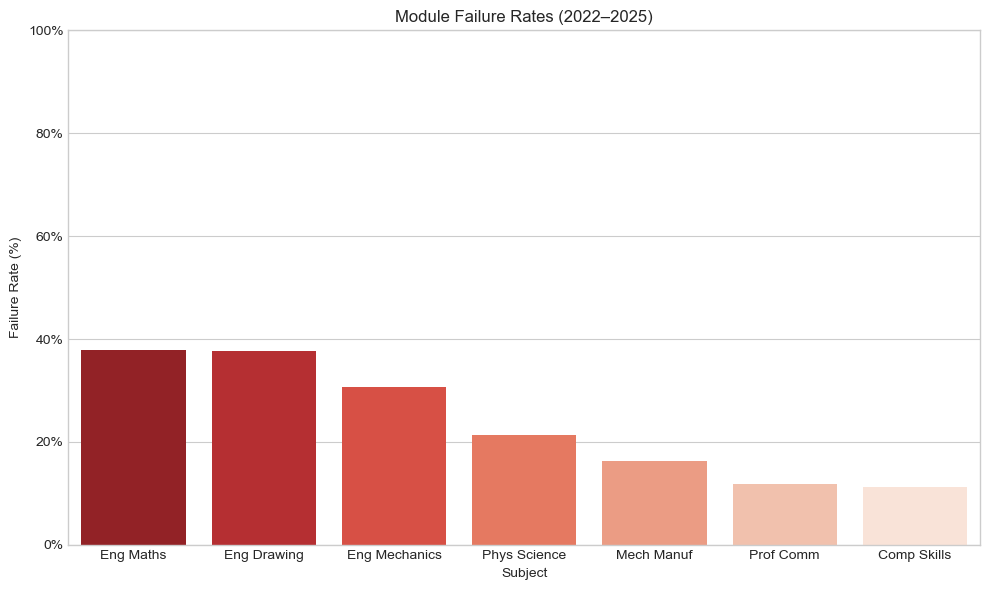

In [120]:
# Overall module failure rates
overall_rows = []
for m in MODULES:
    col = df[m]
    valid = col.dropna()
    n = len(valid)
    fail = (valid < PASS_MARK).sum()
    overall_rows.append({
        'Module': m,
        'Short name': SHORT[m],
        'N students': n,
        'N failed': fail,
        'N passed': n - fail,
        'Failure rate (%)': round(fail / n * 100, 1) if n else np.nan,
        'Pass rate (%)': round((n - fail) / n * 100, 1) if n else np.nan,
        'Missing marks': df[m].isnull().sum(),
    })

overall_df = (pd.DataFrame(overall_rows)
              .sort_values('Failure rate (%)', ascending=False)
              .reset_index(drop=True))

print('Overall module failure rates (2022–2025):')
print(overall_df[['Module','N students','N failed','Failure rate (%)','Missing marks']]
      .to_string(index=False))

# also show this as visulalization
plt.figure(figsize=(10, 6))
sns.barplot(
    data=overall_df,
    x='Short name',
    y='Failure rate (%)',
    palette='Reds_r'
)
plt.title('Module Failure Rates (2022–2025)')
plt.ylabel('Failure Rate (%)')
plt.xlabel('Subject')
plt.ylim(0, 100)
plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter())
plt.tight_layout()
plt.show()

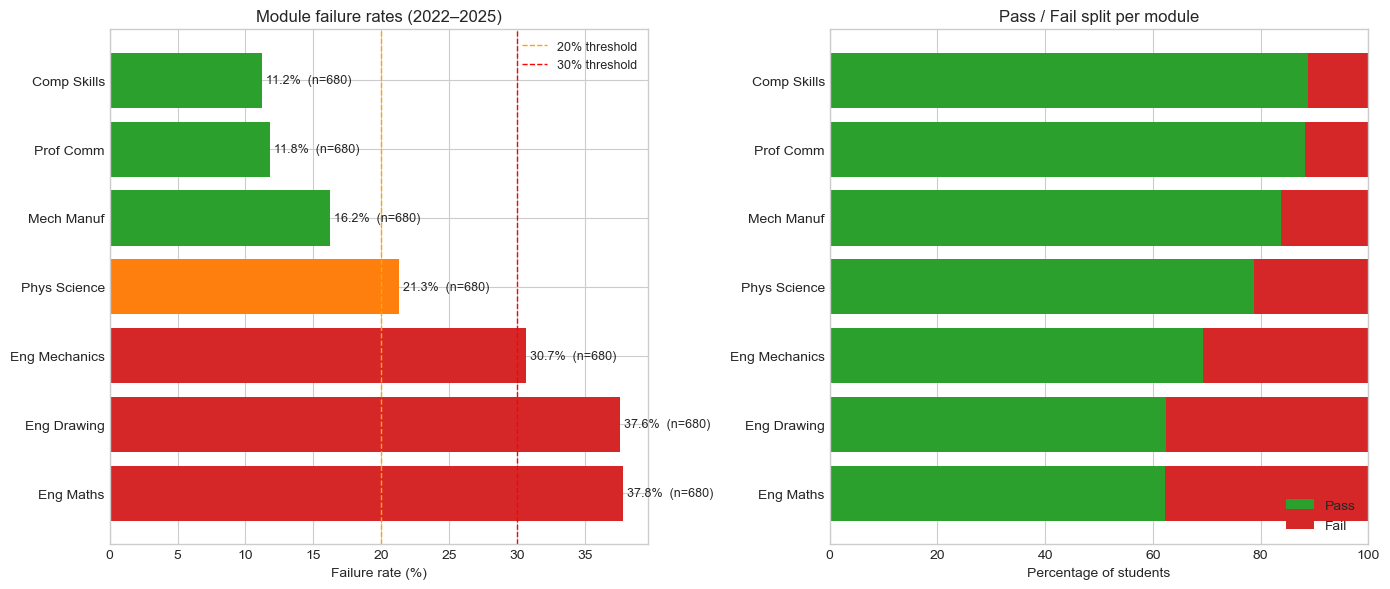

In [121]:
# Bar Chart + stacked pass/fail chart
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

colors = ['#d62728' if r >= 30 else '#ff7f0e' if r >= 20 else '#2ca02c'
          for r in overall_df['Failure rate (%)']]
axes[0].barh(overall_df['Short name'], overall_df['Failure rate (%)'], color=colors)
axes[0].axvline(20, color='orange', linestyle='--', linewidth=1, label='20% threshold')
axes[0].axvline(30, color='red', linestyle='--', linewidth=1, label='30% threshold')
axes[0].set_xlabel('Failure rate (%)')
axes[0].set_title('Module failure rates (2022–2025)')
axes[0].legend(fontsize=9)
for i, (rate, n) in enumerate(zip(overall_df['Failure rate (%)'], overall_df['N students'])):
    axes[0].text(rate + 0.3, i, f'{rate}%  (n={n})', va='center', fontsize=9)

axes[1].barh(overall_df['Short name'], overall_df['Pass rate (%)'], color='#2ca02c', label='Pass')
axes[1].barh(overall_df['Short name'], overall_df['Failure rate (%)'],
             left=overall_df['Pass rate (%)'], color='#d62728', label='Fail')
axes[1].set_xlabel('Percentage of students')
axes[1].set_title('Pass / Fail split per module')
axes[1].legend(loc='lower right')
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.show()

In [122]:
#  Yearly failure rates per module
yearly_rows = []
for year in sorted(df['Academic Year'].unique()):
    ydf = df[df['Academic Year'] == year]
    for m in MODULES:
        valid = ydf[m].dropna()
        n = len(valid)
        fail = (valid < PASS_MARK).sum()
        yearly_rows.append({
            'Academic Year': year,
            'Module': m,
            'Short name': SHORT[m],
            'N students': n,
            'N failed': fail,
            'Failure rate (%)': round(fail / n * 100, 1) if n else np.nan,
        })

yearly_df = pd.DataFrame(yearly_rows)

pivot = yearly_df.pivot(index='Short name', columns='Academic Year', values='Failure rate (%)')
pivot['Mean'] = pivot.mean(axis=1)
pivot = pivot.sort_values('Mean', ascending=False).drop(columns='Mean')
print(pivot.to_string())

Academic Year  2022  2023  2024  2025
Short name                           
Eng Drawing    36.1  40.7  36.6  37.4
Eng Maths      31.9  28.9  32.9  47.9
Eng Mechanics  35.3  32.6  24.8  31.3
Phys Science   41.2  10.4  16.8  20.8
Mech Manuf     12.6   9.6  28.0  14.0
Prof Comm      10.9  20.7   3.7  12.5
Comp Skills     9.2  11.1   6.2  15.1


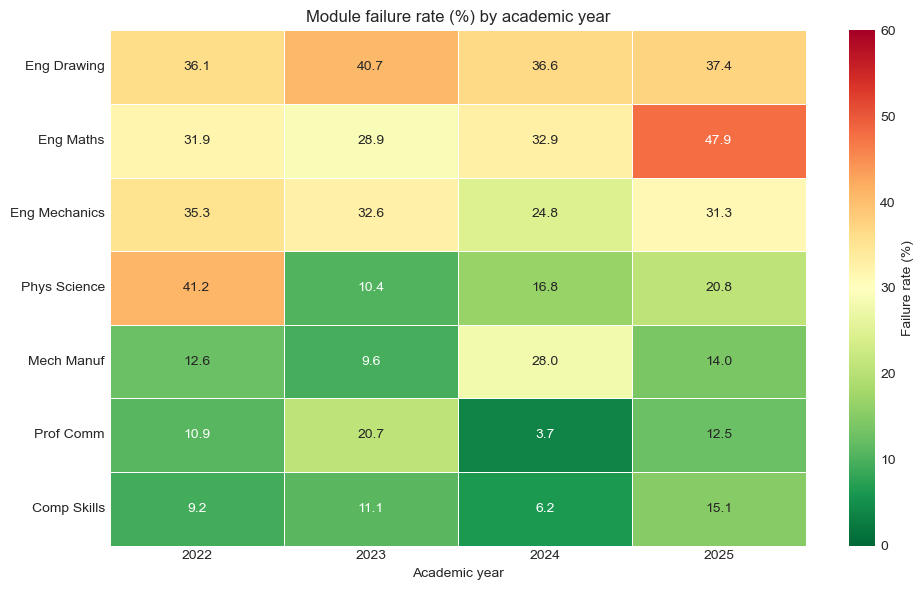

In [123]:
# Visualize module failure rates by academic year
plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='RdYlGn_r',
            linewidths=0.5, vmin=0, vmax=60,
            cbar_kws={'label': 'Failure rate (%)'})
plt.title('Module failure rate (%) by academic year')
plt.ylabel('')
plt.xlabel('Academic year')
plt.tight_layout()
plt.show()

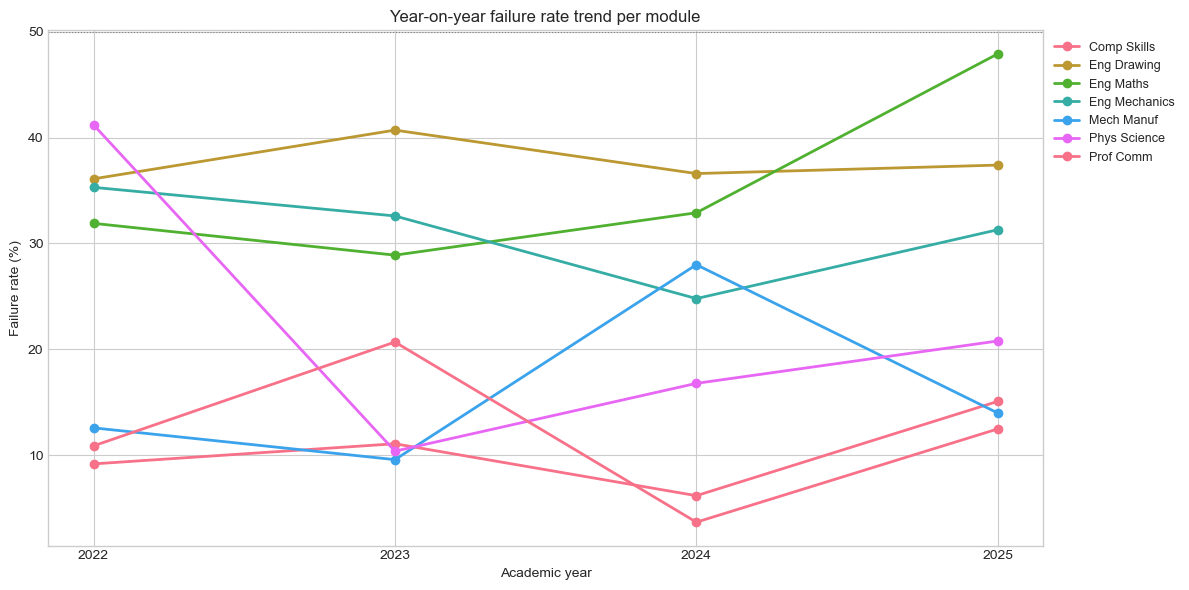

Trend direction per module (positive = worsening):
  Comp Skills        slope=+1.28  WORSENING
  Eng Drawing        slope=-0.02  STABLE
  Eng Maths          slope=+5.20  WORSENING
  Eng Mechanics      slope=-1.98  IMPROVING
  Mech Manuf         slope=+2.26  WORSENING
  Phys Science       slope=-5.48  IMPROVING
  Prof Comm          slope=-1.22  IMPROVING


In [124]:
# Year-on-year failure rate trend per module
fig, ax = plt.subplots(figsize=(12, 6))
years = sorted(df['Academic Year'].unique())

for m in MODULES:
    sub = yearly_df[yearly_df['Module'] == m].sort_values('Academic Year')
    ax.plot(sub['Academic Year'], sub['Failure rate (%)'],
            marker='o', linewidth=2, label=SHORT[m])

ax.axhline(PASS_MARK, color='gray', linestyle=':', linewidth=0.8)
ax.set_xlabel('Academic year')
ax.set_ylabel('Failure rate (%)')
ax.set_title('Year-on-year failure rate trend per module')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=9)
ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.tight_layout()
plt.show()

print('Trend direction per module (positive = worsening):')
for m in MODULES:
    sub = yearly_df[yearly_df['Module'] == m].sort_values('Academic Year')
    rates = sub['Failure rate (%)'].values
    if len(rates) >= 2:
        slope = np.polyfit(range(len(rates)), rates, 1)[0]
        direction = 'WORSENING' if slope > 1 else ('IMPROVING' if slope < -1 else 'STABLE')
        print(f'  {SHORT[m]:<18} slope={slope:+.2f}  {direction}')

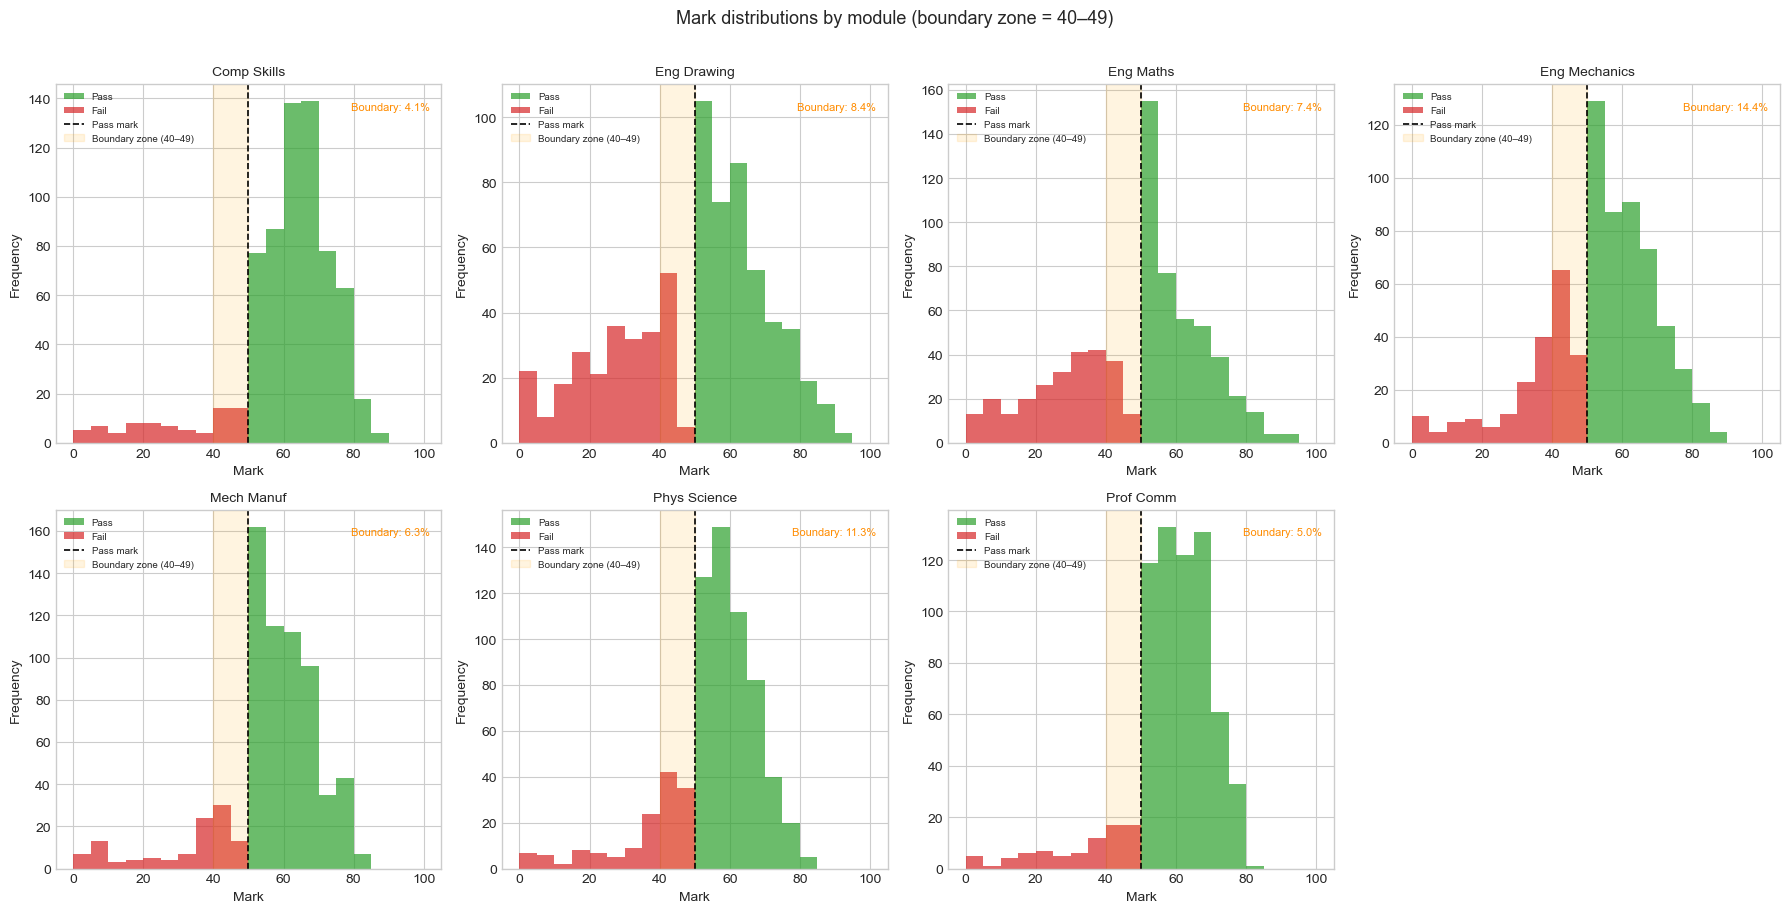

In [125]:
# Pass Mark Distribution Plots
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, m in enumerate(MODULES):
    ax = axes[i]
    marks = df[m].dropna()
    fail = marks[marks < PASS_MARK]
    pass_ = marks[marks >= PASS_MARK]

    ax.hist(pass_.values, bins=20, range=(0, 100), color='#2ca02c', alpha=0.7, label='Pass')
    ax.hist(fail.values, bins=20, range=(0, 100), color='#d62728', alpha=0.7, label='Fail')
    ax.axvline(PASS_MARK, color='black', linestyle='--', linewidth=1.2, label='Pass mark')
    ax.axvspan(40, 50, alpha=0.12, color='orange', label='Boundary zone (40–49)')
    ax.set_title(SHORT[m], fontsize=10)
    ax.set_xlabel('Mark')
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=7)

    boundary = ((marks >= 40) & (marks < 50)).sum()
    pct = boundary / len(marks) * 100 if len(marks) else 0
    ax.text(0.97, 0.95, f'Boundary: {pct:.1f}%',
            transform=ax.transAxes, ha='right', va='top',
            fontsize=8, color='darkorange')

for j in range(len(MODULES), len(axes)):
    axes[j].axis('off')

plt.suptitle('Mark distributions by module (boundary zone = 40–49)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [126]:
#  BOUNDARY ZONE ANALYSIS (40–49 MARKS)
boundary_rows = []
for m in MODULES:
    marks = df[m].dropna()
    n = len(marks)
    boundary = ((marks >= 40) & (marks < PASS_MARK)).sum()
    deep_fail = (marks < 40).sum()
    boundary_rows.append({
        'Module': SHORT[m],
        'N students': n,
        'Deep fail (<40)': deep_fail,
        'Deep fail (%)': round(deep_fail / n * 100, 1) if n else np.nan,
        'Boundary (40–49)': boundary,
        'Boundary (%)': round(boundary / n * 100, 1) if n else np.nan,
        'Mean mark': round(marks.mean(), 1),
        'Median mark': round(marks.median(), 1),
    })

boundary_df = (pd.DataFrame(boundary_rows)
               .sort_values('Boundary (%)', ascending=False)
               .reset_index(drop=True))

print('Boundary zone analysis (students scoring 40–49):')
print(boundary_df.to_string(index=False))

Boundary zone analysis (students scoring 40–49):
       Module  N students  Deep fail (<40)  Deep fail (%)  Boundary (40–49)  Boundary (%)  Mean mark  Median mark
Eng Mechanics         680              111           16.3                98          14.4       53.3         55.0
 Phys Science         680               68           10.0                77          11.3       54.8         57.0
  Eng Drawing         680              199           29.3                57           8.4       49.5         53.0
    Eng Maths         680              207           30.4                50           7.4       48.1         51.0
   Mech Manuf         680               67            9.9                43           6.3       55.9         57.0
    Prof Comm         680               46            6.8                34           5.0       58.3         60.0
  Comp Skills         680               48            7.1                28           4.1       60.6         63.0


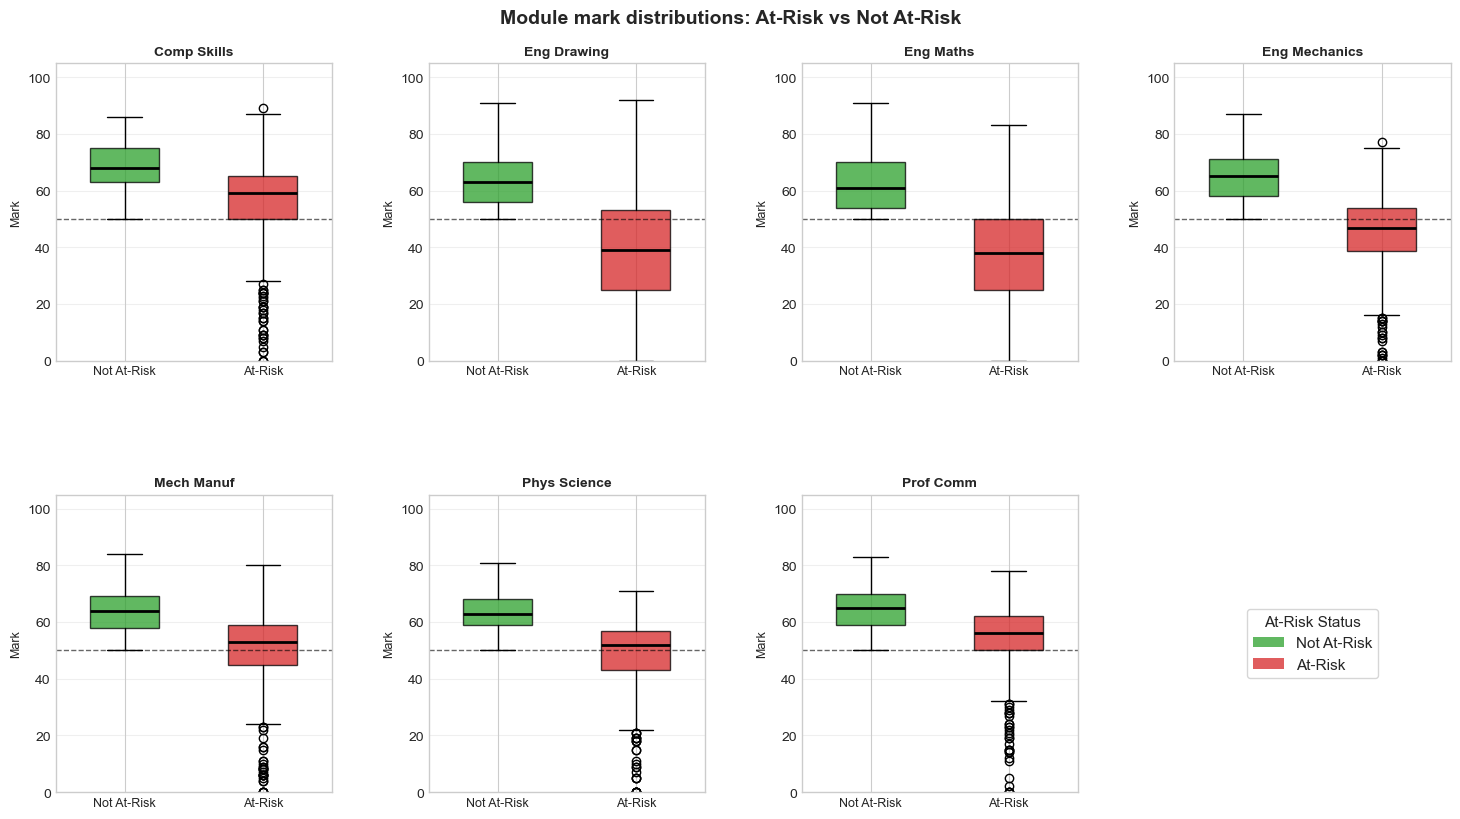

In [127]:
# Box plot for at-risk vs not at-risk students per module
plot_colors = {'No': '#2ca02c', 'Yes': '#d62728'}
plot_order  = ['No', 'Yes']

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, m in enumerate(MODULES):
    ax = axes[i]

    data_no  = df[df['At_Risk'] == 'No'][m].dropna()
    data_yes = df[df['At_Risk'] == 'Yes'][m].dropna()

    bp = ax.boxplot(
        [data_no, data_yes],
        positions=[0, 1],
        widths=0.5,
        patch_artist=True,
        notch=False,
        medianprops=dict(color='black', linewidth=2),
    )

    for patch, key in zip(bp['boxes'], plot_order):
        patch.set_facecolor(plot_colors[key])
        patch.set_alpha(0.75)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Not At-Risk', 'At-Risk'], fontsize=9)
    ax.set_title(SHORT[m], fontsize=10, fontweight='bold')
    ax.set_ylabel('Mark', fontsize=9)
    ax.axhline(y=50, color='black', linestyle='--',
               linewidth=1, alpha=0.6, label='Pass mark')
    ax.set_ylim(0, 105)
    ax.grid(True, axis='y', alpha=0.3)

# Hide the unused 8th subplot
axes[-1].axis('off')

# Legend on the hidden subplot's position
axes[-1].axis('off')
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=plot_colors['No'],  alpha=0.75, label='Not At-Risk'),
    Patch(facecolor=plot_colors['Yes'], alpha=0.75, label='At-Risk'),
]
axes[-1].legend(handles=legend_elements, loc='center', fontsize=11,
                title='At-Risk Status', title_fontsize=11, frameon=True)

plt.suptitle('Module mark distributions: At-Risk vs Not At-Risk',
             fontsize=14, fontweight='bold')
plt.subplots_adjust(hspace=0.45, wspace=0.35, top=0.92)
plt.show()

In [105]:
# CO-FAILURE ANALYSIS
fail_matrix = (df[MODULES] < PASS_MARK).astype(float)
fail_matrix[df[MODULES].isnull()] = np.nan

co_rows = []
for m1, m2 in combinations(MODULES, 2):
    both = (fail_matrix[m1] == 1) & (fail_matrix[m2] == 1)
    union = (fail_matrix[m1] == 1) | (fail_matrix[m2] == 1)
    co_fail = both.sum()
    union_n = union.sum()
    jaccard = co_fail / union_n if union_n > 0 else 0
    co_rows.append({
        'Module A': SHORT[m1],
        'Module B': SHORT[m2],
        'Co-fail count': int(co_fail),
        'Union count': int(union_n),
        'Jaccard (%)': round(jaccard * 100, 1),
    })

co_df = (pd.DataFrame(co_rows)
         .sort_values('Jaccard (%)', ascending=False)
         .reset_index(drop=True))

print('Top 15 co-failing module pairs (by Jaccard similarity):')
print(co_df.head(15).to_string(index=False))

Top 15 co-failing module pairs (by Jaccard similarity):
     Module A      Module B  Co-fail count  Union count  Jaccard (%)
    Eng Maths Eng Mechanics            170          322         52.8
Eng Mechanics  Phys Science            133          255         52.2
  Eng Drawing Eng Mechanics            164          320         51.2
  Eng Drawing     Eng Maths            158          368         42.9
  Comp Skills     Prof Comm             55          133         41.4
    Eng Maths  Phys Science            125          305         41.0
   Mech Manuf  Phys Science             82          204         40.2
Eng Mechanics    Mech Manuf             95          253         37.5
  Comp Skills  Phys Science             68          185         36.8
  Comp Skills    Mech Manuf             57          156         36.5
   Mech Manuf     Prof Comm             57          164         34.8
  Eng Drawing  Phys Science            104          318         32.7
 Phys Science     Prof Comm             62     

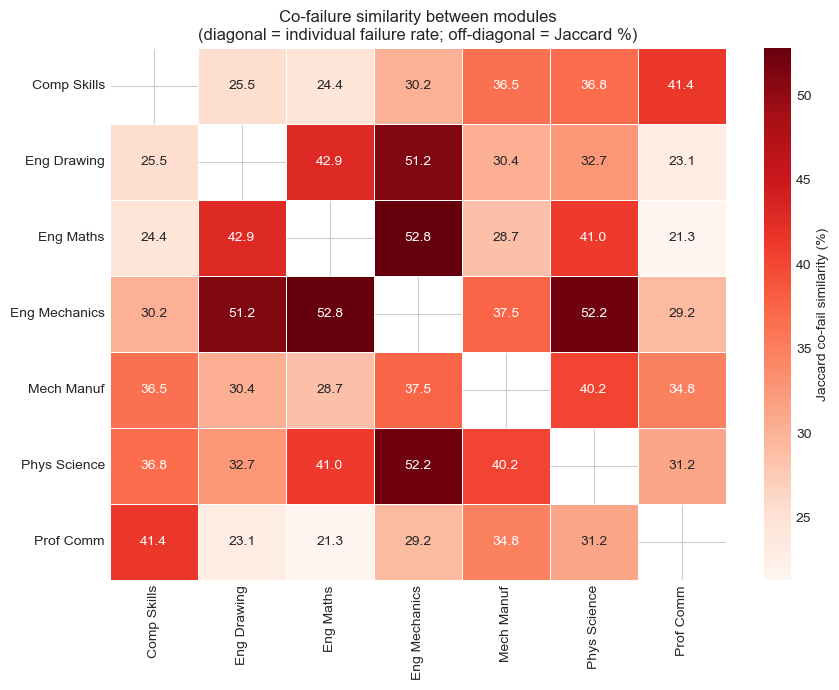

In [106]:
# Create a pivot table for co-failure similarity
cofail_pivot = pd.DataFrame(index=[SHORT[m] for m in MODULES],
                            columns=[SHORT[m] for m in MODULES],
                            dtype=float)
diag_values = [((fail_matrix[m] == 1).sum() / fail_matrix[m].notna().sum() * 100)
               for m in MODULES]
cofail_pivot.iloc[np.arange(len(MODULES)), np.arange(len(MODULES))] = diag_values

for _, row in co_df.iterrows():
    cofail_pivot.loc[row['Module A'], row['Module B']] = row['Jaccard (%)']
    cofail_pivot.loc[row['Module B'], row['Module A']] = row['Jaccard (%)']

plt.figure(figsize=(9, 7))
mask = np.eye(len(MODULES), dtype=bool)
sns.heatmap(cofail_pivot.astype(float), annot=True, fmt='.1f',
            cmap='Reds', mask=mask, linewidths=0.5,
            cbar_kws={'label': 'Jaccard co-fail similarity (%)'})
plt.title('Co-failure similarity between modules\n'
          '(diagonal = individual failure rate; off-diagonal = Jaccard %)')
plt.tight_layout()
plt.show()

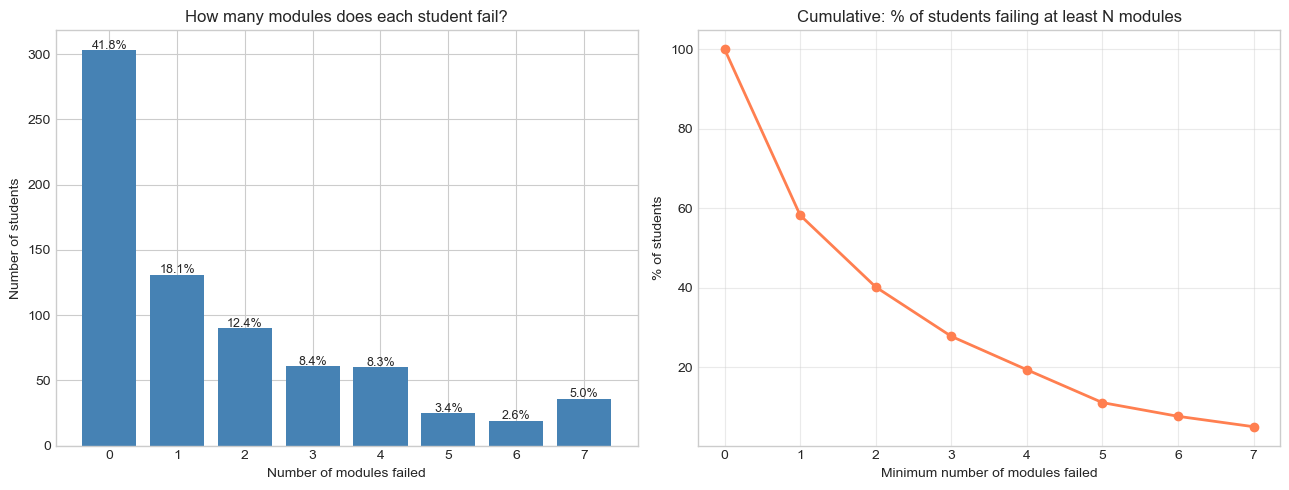

Failure load summary:
  Failed >= 0 module(s): 725 students (100.0%)
  Failed >= 1 module(s): 422 students (58.2%)
  Failed >= 2 module(s): 291 students (40.1%)
  Failed >= 3 module(s): 201 students (27.7%)
  Failed >= 4 module(s): 140 students (19.3%)
  Failed >= 5 module(s): 80 students (11.0%)
  Failed >= 6 module(s): 55 students (7.6%)
  Failed >= 7 module(s): 36 students (5.0%)


In [107]:
# Failure load analysis
fail_counts = fail_matrix.sum(axis=1, skipna=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

counts = fail_counts.value_counts().sort_index()
axes[0].bar(counts.index.astype(int), counts.values, color='steelblue')
axes[0].set_xlabel('Number of modules failed')
axes[0].set_ylabel('Number of students')
axes[0].set_title('How many modules does each student fail?')
axes[0].xaxis.set_major_locator(mticker.MultipleLocator(1))
for xi, yi in zip(counts.index.astype(int), counts.values):
    pct = yi / len(fail_counts) * 100
    axes[0].text(xi, yi + 1, f'{pct:.1f}%', ha='center', fontsize=9)

cumulative = [(fail_counts >= k).mean() * 100 for k in range(0, 8)]
axes[1].plot(range(0, 8), cumulative, marker='o', color='coral', linewidth=2)
axes[1].set_xlabel('Minimum number of modules failed')
axes[1].set_ylabel('% of students')
axes[1].set_title('Cumulative: % of students failing at least N modules')
axes[1].xaxis.set_major_locator(mticker.MultipleLocator(1))
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

print('Failure load summary:')
for k in range(0, 8):
    n = (fail_counts >= k).sum()
    pct = n / len(fail_counts) * 100
    print(f'  Failed >= {k} module(s): {n} students ({pct:.1f}%)')

Bottleneck analysis:
       Module  N failed  Avg other modules failed  Sole failure (%)  Bottleneck score
Eng Mechanics       225                      3.15               3.1             97.66
    Eng Maths       267                      2.52              20.2             92.97
  Eng Drawing       259                      2.52              17.0             90.07
 Phys Science       163                      3.52               8.0             79.17
   Mech Manuf       123                      3.80               4.1             64.41
  Comp Skills        90                      4.38               1.1             54.34
    Prof Comm        98                      3.86               7.1             52.14


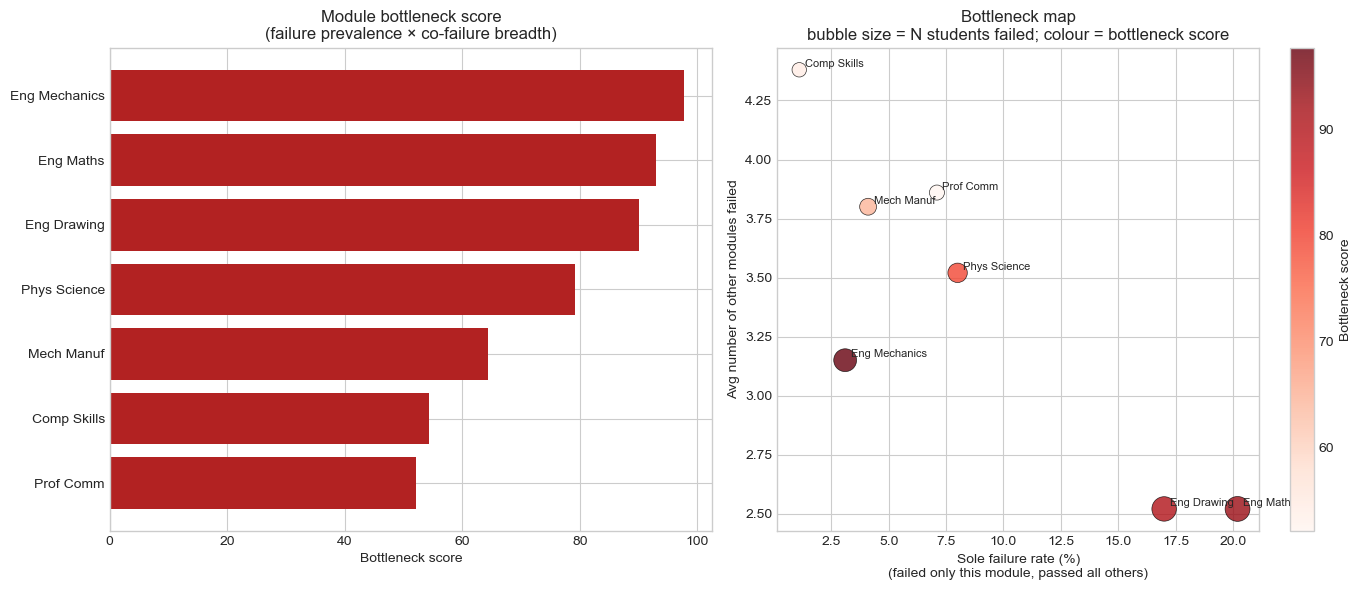

In [108]:
# Bottleneck analysis: which modules are the most critical in terms of co-failure?
bottleneck_rows = []
for m in MODULES:
    failed_m = fail_matrix[fail_matrix[m] == 1]
    n_failed_m = len(failed_m)
    if n_failed_m == 0:
        continue
    other_cols = [c for c in MODULES if c != m]
    other_failures = failed_m[other_cols].sum(axis=1, skipna=True)
    avg_other = other_failures.mean()
    sole_failures = (other_failures == 0).sum()
    sole_pct = sole_failures / n_failed_m * 100

    cond_rates = {}
    for o in other_cols:
        both = ((fail_matrix[m] == 1) & (fail_matrix[o] == 1)).sum()
        cond = both / n_failed_m * 100 if n_failed_m else 0
        cond_rates[SHORT[o]] = round(cond, 1)

    bottleneck_rows.append({
        'Module': SHORT[m],
        'N failed': n_failed_m,
        'Avg other modules failed': round(avg_other, 2),
        'Sole failure (%)': round(sole_pct, 1),
        'Bottleneck score': round(avg_other * (n_failed_m / len(df)) * 100, 2),
        **{f'P(fail {k} | fail this)': v for k, v in cond_rates.items()}
    })

bottleneck_df = (pd.DataFrame(bottleneck_rows)
                 .sort_values('Bottleneck score', ascending=False)
                 .reset_index(drop=True))

summary_cols = ['Module','N failed','Avg other modules failed',
                'Sole failure (%)','Bottleneck score']
print('Bottleneck analysis:')
print(bottleneck_df[summary_cols].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(bottleneck_df['Module'], bottleneck_df['Bottleneck score'], color='firebrick')
axes[0].set_xlabel('Bottleneck score')
axes[0].set_title('Module bottleneck score\n(failure prevalence × co-failure breadth)')
axes[0].invert_yaxis()

sc = axes[1].scatter(bottleneck_df['Sole failure (%)'],
                     bottleneck_df['Avg other modules failed'],
                     s=bottleneck_df['N failed'] * 1.2,
                     c=bottleneck_df['Bottleneck score'],
                     cmap='Reds', alpha=0.8, edgecolors='black', linewidths=0.5)
for _, row in bottleneck_df.iterrows():
    axes[1].annotate(row['Module'],
                     (row['Sole failure (%)'], row['Avg other modules failed']),
                     fontsize=8, ha='left',
                     xytext=(4, 2), textcoords='offset points')
plt.colorbar(sc, ax=axes[1], label='Bottleneck score')
axes[1].set_xlabel('Sole failure rate (%)\n(failed only this module, passed all others)')
axes[1].set_ylabel('Avg number of other modules failed')
axes[1].set_title('Bottleneck map\nbubble size = N students failed; colour = bottleneck score')

plt.tight_layout()
plt.show()

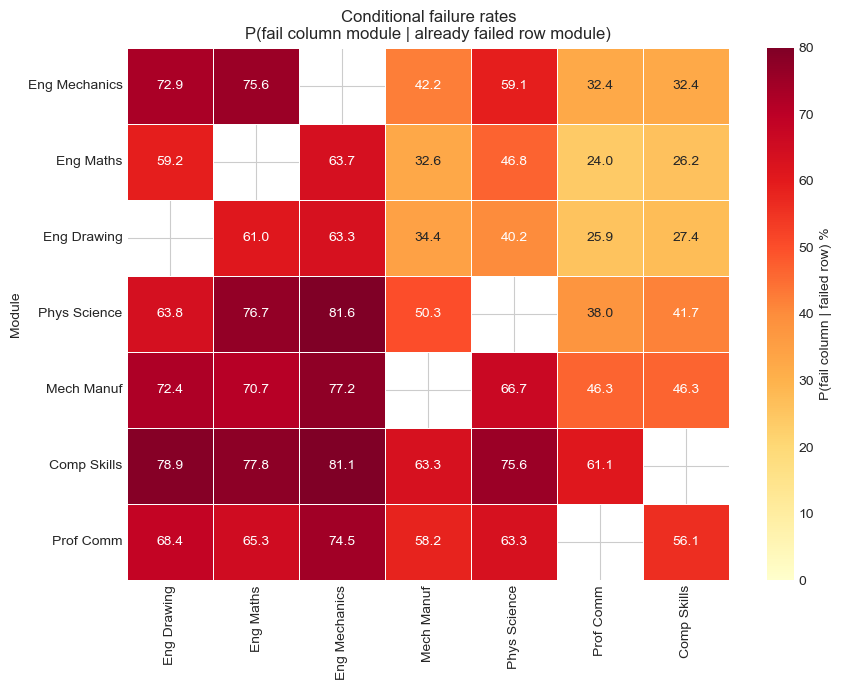

In [109]:
# Conditional failure rates heatmap
cond_cols = [c for c in bottleneck_df.columns if c.startswith('P(fail')]
cond_pivot = bottleneck_df.set_index('Module')[cond_cols].copy()
cond_pivot.columns = [c.replace('P(fail ','').replace(' | fail this)','')
                      for c in cond_pivot.columns]

plt.figure(figsize=(9, 7))
sns.heatmap(cond_pivot.astype(float), annot=True, fmt='.1f',
            cmap='YlOrRd', linewidths=0.5, vmin=0, vmax=80,
            cbar_kws={'label': 'P(fail column | failed row) %'})
plt.title('Conditional failure rates\nP(fail column module | already failed row module)')
plt.tight_layout()
plt.show()

In [110]:
# Summary table combining overall, yearly, boundary, and bottleneck analyses
summary = overall_df[['Module','N students','N failed','Failure rate (%)','Pass rate (%)']].copy()

yr_range = (yearly_df.groupby('Module')['Failure rate (%)']
              .agg(Min_year_rate=('min'), Max_year_rate=('max'))
              .reset_index())
summary = summary.merge(yr_range, on='Module', how='left')

boundary_map = boundary_df.rename(
    columns={'Module': 'Short name', 'Boundary (%)': 'Boundary zone (%)'}
)[['Short name','Boundary zone (%)']]
summary['Short name'] = summary['Module'].map(SHORT)
summary = summary.merge(boundary_map, on='Short name', how='left')

bn_map = bottleneck_df[['Module','Bottleneck score']].copy()
bn_map['Module'] = bn_map['Module'].map({v: k for k, v in SHORT.items()})
summary = summary.merge(bn_map, on='Module', how='left')

summary = summary.drop(columns='Short name').sort_values(
    'Failure rate (%)', ascending=False).reset_index(drop=True)

print('FULL SUMMARY TABLE — Subject Analysis')
print('='*90)
print(summary.to_string(index=False))

FULL SUMMARY TABLE — Subject Analysis
                              Module  N students  N failed  Failure rate (%)  Pass rate (%)  Min_year_rate  Max_year_rate  Boundary zone (%)  Bottleneck score
               ENGINEERING DRAWING 1         685       259              37.8           62.2           36.4           40.4                8.3             90.07
             ENGINEERING MATHEMATICS         715       267              37.3           62.7           26.9           49.1                7.4             92.97
               ENGINEERING MECHANICS         718       225              31.3           68.7           24.5           35.1               14.1             97.66
                    PHYSICAL SCIENCE         717       163              22.7           77.3            9.8           41.8               11.4             79.17
MECHANICAL ENGINEERING MANUFACTURING         712       123              17.3           82.7           10.5           28.2                6.7             64.41
        

## Per-Year Model Performance

Trains and evaluates SVM and Random Forest **separately on each academic-year
cohort** (2022-2025), using stratified k-fold cross-validation within each year
rather than a single train/test split -- each cohort only has roughly 150-250
students, too few for a reliable held-out test set on its own.

This checks whether predictive performance is stable across cohorts, or whether
some years are harder to predict than others (worth relating back to the
Engineering Mathematics failure-rate spike seen in the module analysis).

In [111]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

def evaluate_by_year(pipeline, model_name, X_full, y_full, n_splits=5):
    """
    Runs stratified k-fold CV separately for each Academic Year present in X_full.
    Returns a tidy DataFrame: one row per (Year, Model) with mean CV metrics.

    'Academic Year' is left in the feature set (it becomes a constant column
    within each year-specific subset, which scikit-learn's scaler/encoders
    handle without error -- it is simply uninformative for that year).
    """
    results = []
    scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

    for year in sorted(X_full['Academic Year'].dropna().unique()):
        mask = X_full['Academic Year'] == year
        X_year = X_full.loc[mask].copy()
        y_year = y_full.loc[mask]

        n = len(y_year)
        n_pos = int(y_year.sum())
        n_neg = n - n_pos
        min_class = min(n_pos, n_neg)

        if min_class < 2:
            print(f"Skipping {year}: not enough samples in the minority class ({min_class}).")
            continue

        # Reduce folds if the minority class is smaller than n_splits
        folds = min(n_splits, min_class)
        cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=42)

        model = clone(pipeline)
        scores = cross_validate(model, X_year, y_year, cv=cv, scoring=scoring, n_jobs=-1)

        results.append({
            'Year': year,
            'Model': model_name,
            'N': n,
            'At-Risk %': round(100 * n_pos / n, 1),
            'Folds': folds,
            'Accuracy': scores['test_accuracy'].mean(),
            'Precision': scores['test_precision'].mean(),
            'Recall': scores['test_recall'].mean(),
            'F1-Score': scores['test_f1'].mean(),
            'ROC-AUC': scores['test_roc_auc'].mean(),
        })

    return pd.DataFrame(results)


# X should never need rebuilding here -- nothing between the "TRAIN-TEST
# SPLIT" cell and here legitimately reassigns X or y. If either check below
# fails, something upstream overwrote them (e.g. a stray `for x, y in ...`
# loop) -- re-run the "TRAIN-TEST SPLIT" cell, then re-run this cell. Do NOT
# rebuild X/y from `df` here: by this point in the notebook, the Module
# Analysis section has already reassigned `df` to a stripped-down 12-column
# frame that is missing most of the modelling features.
assert isinstance(X, pd.DataFrame), (
    "X is not a DataFrame. Re-run the 'TRAIN-TEST SPLIT' cell above, then re-run this cell."
)
assert isinstance(y, pd.Series), (
    "y is not a Series -- something overwrote it (check for stray 'for x, y in ...' loops "
    "elsewhere in the notebook). Re-run the 'TRAIN-TEST SPLIT' cell, then re-run this cell."
)
assert 'Academic Year' in X.columns, "'Academic Year' column missing from X."
assert len(X) == len(y), f"X has {len(X)} rows but y has {len(y)} rows -- out of sync."

print("Evaluating SVM per year...")

# Ensure y is binary numeric (0/1), and align X/y in case any rows have an
# invalid/missing target or a missing Academic Year after the checks above.
y = y.replace({'Yes': 1, 'No': 0})
y = pd.to_numeric(y, errors='coerce')

valid_mask = y.notna() & X['Academic Year'].notna()
if valid_mask.sum() != len(y):
    print(f"Dropping {len(y) - valid_mask.sum()} row(s) with an invalid target or missing Academic Year.")
    X = X.loc[valid_mask].copy()
    y = y.loc[valid_mask].copy()

y = y.astype(int)

svm_by_year = evaluate_by_year(svm_model, 'SVM', X, y)

print("Evaluating Random Forest per year...")
rf_by_year = evaluate_by_year(rf_model, 'Random Forest', X, y)

by_year_results = pd.concat([svm_by_year, rf_by_year], ignore_index=True)
by_year_results = by_year_results.round(4)
display(by_year_results)


Evaluating SVM per year...


Evaluating Random Forest per year...


,Year,Model,N,At-Risk %,Folds,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,2022,SVM,119,58.8,5,0.9406,0.9437,0.9571,0.9497,0.9719
1,2023,SVM,135,54.1,5,0.8667,0.8768,0.8790,0.8758,0.9656
2,2024,SVM,161,59.0,5,0.9379,0.9684,0.9263,0.9462,0.9921
3,2025,SVM,265,58.1,5,0.9170,0.9652,0.8892,0.9255,0.9819
4,2022,Random Forest,119,58.8,5,0.9409,0.9571,0.9429,0.9497,0.9811
5,2023,Random Forest,135,54.1,5,0.8963,0.9029,0.9057,0.9034,0.9667
6,2024,Random Forest,161,59.0,5,0.9070,0.9379,0.9053,0.9203,0.9788
7,2025,Random Forest,265,58.1,5,0.9736,0.9750,0.9806,0.9774,0.9950


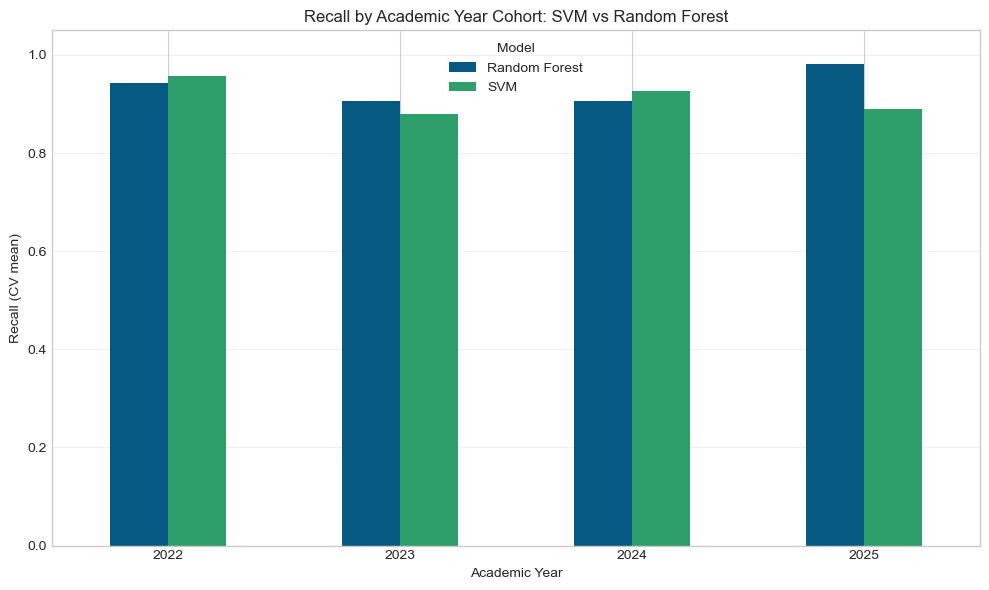

Note: each year is evaluated independently -- a separate model is trained
and cross-validated only on that year's cohort. This shows whether predictive
performance holds up across cohorts, not how well a single model trained on
all years generalises to a specific year.


In [112]:
# Visualize recall by year for both models
pivot_recall = by_year_results.pivot(index='Year', columns='Model', values='Recall')

fig, ax = plt.subplots(figsize=(10, 6))
pivot_recall.plot(kind='bar', ax=ax, color=['#065A82', '#2E9E6B'], rot=0)
ax.set_title('Recall by Academic Year Cohort: SVM vs Random Forest')
ax.set_ylabel('Recall (CV mean)')
ax.set_xlabel('Academic Year')
ax.set_ylim(0, 1.05)
ax.legend(title='Model')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("Note: each year is evaluated independently -- a separate model is trained")
print("and cross-validated only on that year's cohort. This shows whether predictive")
print("performance holds up across cohorts, not how well a single model trained on")
print("all years generalises to a specific year.")


### Digging into the 2023 dip and 2025 divergence

Two things stand out in the per-year table above:

1. **2023 is the weakest cohort for both models** (lowest recall of any year, for both SVM and Random Forest).
2. **2025 is where the two models diverge most** -- Random Forest pulls well ahead of SVM.

The cells below pull the actual per-year numbers behind both observations, rather than guessing.

In [113]:
# --- Evidence 1: class balance per year ---
# (this is the "At-Risk %" column already computed in by_year_results,
# isolated here for a direct look)

balance_by_year = by_year_results[by_year_results['Model'] == 'SVM'][['Year', 'N', 'At-Risk %']].reset_index(drop=True)
print("Class balance by year (At-Risk %):")
display(balance_by_year)

print("\n2023 sits closest to a 50/50 split -- every other year is 8-9 points further")
print("from balanced. A model has the least 'dominant class to lean on' in the year")
print("where the split is most even, which alone would predict weaker recall in 2023.")


Class balance by year (At-Risk %):


,Year,N,At-Risk %
0,2022,119,58.8
1,2023,135,54.1
2,2024,161,59.0
3,2025,265,58.1



2023 sits closest to a 50/50 split -- every other year is 8-9 points further
from balanced. A model has the least 'dominant class to lean on' in the year
where the split is most even, which alone would predict weaker recall in 2023.


In [114]:
# --- Evidence 2: does 2023's *pattern* of module failure also look different? ---
# Reuses `pivot` from the Module Analysis section above (module failure rate
# by academic year). Requires that section to have been run first.

print("Module failure rate (%) by year:")
display(pivot)

print("\nYear-over-year change relative to the other three years' average:")
other_years_avg = pivot.drop(columns=[2023]).mean(axis=1)
deviation_2023 = (pivot[2023] - other_years_avg).sort_values()
display(deviation_2023.rename("2023 vs avg of other years (pp)").to_frame())


Module failure rate (%) by year:


Academic Year,2022,2023,2024,2025
Short name,,,,
Eng Drawing,36.4,40.4,36.6,37.8
Eng Maths,29.9,26.9,33.1,49.1
Eng Mechanics,35.1,30.3,24.5,34.1
Phys Science,41.8,9.8,16.6,23.8
Mech Manuf,13.5,10.5,28.2,16.1
Prof Comm,13.3,21.2,3.7,15.6
Comp Skills,10.4,10.4,6.1,18.3



Year-over-year change relative to the other three years' average:


,2023 vs avg of other years (pp)
Short name,
Phys Science,-17.600000
Eng Maths,-10.466667
Mech Manuf,-8.766667
Comp Skills,-1.200000
Eng Mechanics,-0.933333
Eng Drawing,3.466667
Prof Comm,10.333333


**Reading 2023:** it isn't just closer to a 50/50 split -- the *shape* of risk that year is
unusual too. Engineering Mathematics, Engineering Mechanics, Physical Science, and Mechanical
Manufacturing all sit noticeably *below* their typical rate, while Engineering Drawing 1 spikes to
its highest failure rate of any year. Since both models learned their patterns mostly from what's
typical across the majority of the dataset, a year where the usual top predictors (Eng Maths, Eng
Mechanics) are relatively quiet, and a normally-secondary module (Eng Drawing) carries an unusually
large share of the risk signal, is exactly the kind of year a model would find harder to separate
cleanly. Combined with the closer-to-even class balance, this gives two independent, compounding
reasons for the recall dip -- not just one.

In [115]:
# --- Evidence 3: what's different about 2025? ---

print("Engineering Mathematics failure rate by year:")
display(pivot.loc['Eng Maths'])

print("\n2025 cohort size vs other years:")
display(balance_by_year.set_index('Year')['N'])

# Boundary-zone concentration specifically within 2025 (marks 40-49, i.e.
# "so close to passing" cases), to see if 2025 has an unusually large
# cluster of students sitting right at the pass/fail line in Eng Maths.
maths_2025 = df.loc[df['Academic Year'] == 2025, 'ENGINEERING MATHEMATICS'].dropna()
boundary_2025 = ((maths_2025 >= 40) & (maths_2025 < PASS_MARK)).sum()
deep_fail_2025 = (maths_2025 < 40).sum()
print(f"\n2025 Engineering Mathematics (n={len(maths_2025)}):")
print(f"  Boundary zone (40-49): {boundary_2025} students ({boundary_2025/len(maths_2025)*100:.1f}%)")
print(f"  Deep fail (<40):       {deep_fail_2025} students ({deep_fail_2025/len(maths_2025)*100:.1f}%)")


Engineering Mathematics failure rate by year:


Academic Year
2022    29.9
2023    26.9
2024    33.1
2025    49.1
Name: Eng Maths, dtype: float64


2025 cohort size vs other years:


Year
2022    119
2023    135
2024    161
2025    265
Name: N, dtype: int64


2025 Engineering Mathematics (n=273):
  Boundary zone (40-49): 18 students (6.6%)
  Deep fail (<40):       116 students (42.5%)


**Reading 2025:** Engineering Mathematics -- already the single strongest predictor across the
whole project -- nearly doubles its failure rate from 2024 (33.1%) to 2025 (49.1%). That's close to
half the cohort failing the one module both models lean on most heavily, in the largest cohort in
the dataset (N=280, roughly double most other years). A large, clear swing in the strongest single
feature, backed by more training rows than any other year, is exactly the kind of signal a
threshold-splitting model like Random Forest is structurally well-suited to exploit -- its trees can
carve a hard `Eng Maths <= X` cutoff directly. SVM's RBF kernel builds a smoother boundary that
doesn't capture a hard pass/fail cutoff as cleanly, particularly for the students sitting right at
that boundary.

**Worth flagging as a hypothesis, not a settled conclusion:** SVM's `C=1.0` regularization strength
was fixed rather than re-tuned per year (`gamma='scale'` does auto-adjust to each year's feature
variance, but `C` doesn't). It's plausible that a fixed regularization strength is simply less
well-matched to 2025's shifted distribution than it is to the other years. If you want to test this
rather than just note it, the cleanest way is to add a small per-year `C` grid search (e.g. `C in
[0.1, 1, 10]`, picked by inner CV) inside `evaluate_by_year` for SVM only, and see whether the 2025
recall gap narrows once `C` is allowed to adapt.